# Семинар 5. Детекция объектов
## Глубинное Обучение-1, ФКН ВШЭ

В ходе семинара рассмотрим 2 архитектуры и 2 датасета: Faster R-CNN на PASCAL VOC и готовая YOLOv8 на кадрах квиддича из «Гарри Поттера».

### 1. Постановка задачи

**Вход:** изображение.

**Разметка:** класс и ограничивающий прямоугольник (*bounding box* - бибокс) для каждого объекта.

**Выход:** боксы, классы и оценки уверенности; число объектов заранее неизвестно.

В отличие от сегментации, детекция не восстанавливает точный контур: внутри бокса остаётся и фон. Для дыма, разливов, облаков и других аморфных областей маска часто содержательнее прямоугольника. Маленькие объекты, перекрытия и плотные группы тоже усложняют детекцию.

In [14]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

### 2. Боксы и метрики

В формате `xyxy` бокс хранится как $(x_{min},y_{min},x_{max},y_{max})$ в пикселях. Начало координат — левый верхний угол, $x$ растёт вправо, $y$ — вниз. В YOLO-разметке используются центр и размеры, нормированные на ширину и высоту изображения.

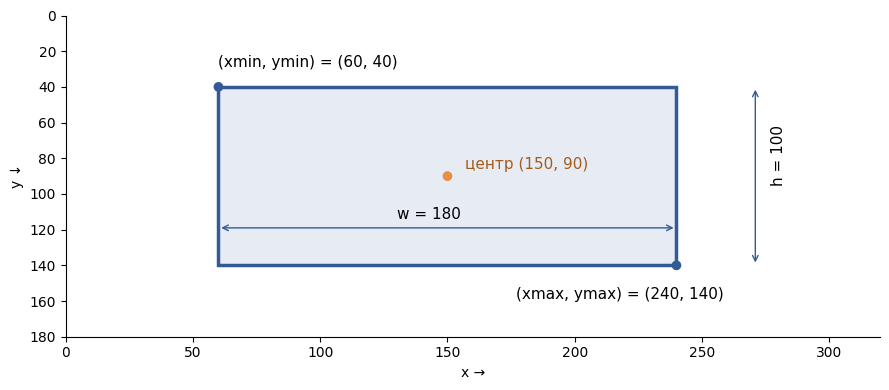

In [15]:
# посмотрим на геометрию бокса: координаты углов, центр и размеры.

fig, ax = plt.subplots(figsize=(9, 4))
ax.set(xlim=(0, 320), ylim=(180, 0), xlabel='x →', ylabel='y ↓')
ax.add_patch(Rectangle((60, 40), 180, 100, color='#5178b7', alpha=0.14))
ax.add_patch(Rectangle((60, 40), 180, 100, fill=False, lw=2.5, edgecolor='#345a96'))
ax.scatter([60, 240, 150], [40, 140, 90], c=['#345a96', '#345a96', '#e69043'], zorder=3)
ax.text(60, 29, '(xmin, ymin) = (60, 40)', fontsize=11)
ax.text(177, 159, '(xmax, ymax) = (240, 140)', fontsize=11)
ax.text(157, 86, 'центр (150, 90)', fontsize=11, color='#a45c1a')
ax.annotate('', (60, 119), (240, 119), arrowprops=dict(arrowstyle='<->', color='#345a96'))
ax.text(130, 114, 'w = 180', fontsize=11)
ax.annotate('', (271, 40), (271, 140), arrowprops=dict(arrowstyle='<->', color='#345a96'))
ax.text(280, 94, 'h = 100', rotation=90, ha='center', fontsize=11)
ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
plt.show()

**IoU** — доля пересечения в объединении областей; **Dice** — удвоенное пересечение, делённое на сумму площадей:

$$\mathrm{IoU}(A,B)=\frac{|A\cap B|}{|A\cup B|},\qquad
\mathrm{Dice}(A,B)=\frac{2|A\cap B|}{|A|+|B|}.$$

Обе меры равны 1 при полном совпадении и 0 без пересечения. Dice чаще применяют к маскам; стандартная оценка детекции опирается на IoU. Для тех же областей Dice численно выше, поэтому одинаковые пороги имеют разную строгость.

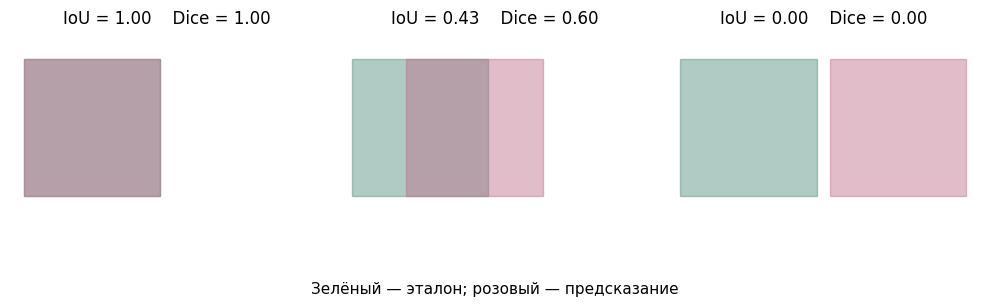

In [16]:
# визуальное сравнение IoU и Dice (одинаковые бибоксы, разное перекрытие)
fig, axes = plt.subplots(1, 3, figsize=(10, 3.2))
for ax, shift in zip(axes, [0, 4, 11]):
    intersection = max(0, 10 - shift) * 10
    iou = intersection / (200 - intersection)
    dice = 2 * intersection / 200
    ax.add_patch(Rectangle((1, 2), 10, 10, color='#4e8c7d', alpha=0.45))
    ax.add_patch(Rectangle((1 + shift, 2), 10, 10, color='#bd6d8b', alpha=0.45))
    ax.set(xlim=(0, 23), ylim=(0, 14), aspect='equal')
    ax.set_title(f'IoU = {iou:.2f}    Dice = {dice:.2f}', fontsize=12)
    ax.axis('off')
fig.text(0.5, 0.02, 'Зелёный — эталон; розовый — предсказание', ha='center', fontsize=11)
fig.tight_layout(rect=(0, 0.08, 1, 1))
plt.show()

### Метрики качества и удаление дубликатов

Бокс считается верным, если класс определён правильно и IoU с эталоном достаточно велик. Один эталонный объект можно засчитать только один раз: повторные боксы считаются ложными предсказаниями.

**AP — качество детекции одного класса**

Детектор выдаёт боксы с оценками уверенности. Меняя порог уверенности, получаем разные значения **Precision** — доли верных предсказаний — и **Recall** — доли найденных настоящих объектов.

AP (*Average Precision*) объединяет эти результаты. Его смысл — площадь под интерполированной Precision–Recall-кривой:

$$
\mathrm{AP}\approx\int_0^1 P_{\mathrm{interp}}(R)\,dR.
$$

Здесь $R$ — Recall, а $P_{\mathrm{interp}}(R)$ — интерполированная Precision. На практике используют дискретный подсчёт, заданный протоколом оценки.

Высокий AP требует находить большую долю объектов и ставить правильные предсказания выше ложных по уверенности.

**mAP — среднее качество по классам**

mAP (*mean Average Precision*) — среднее AP по всем оцениваемым классам:

$$
\mathrm{mAP}=\frac{1}{C}\sum_{c=1}^{C}\mathrm{AP}_c,
$$

где $C$ — число классов, а $\mathrm{AP}_c$ — качество детекции класса $c$.

| Метрика | Как проверяется точность боксов |
|---|---|
| `mAP@0.50` | Для верного совпадения достаточно IoU ≥ 0.50. |
| `mAP@[0.50:0.95]` | Оценка усредняется по порогам IoU 0.50, 0.55, …, 0.95. Требования к точности строже. |

**NMS — удаление повторных боксов**

Один объект может получить несколько похожих предсказаний. NMS (*Non-Maximum Suppression*) обрабатывает каждый класс отдельно:

1. Выбирает бокс с максимальной уверенностью.
2. Удаляет менее уверенные боксы, сильно перекрывающиеся с выбранным:
   $\mathrm{IoU}(B_i,B_{\mathrm{best}})>\tau_{\mathrm{NMS}}$.
3. Повторяет процесс для оставшихся боксов.

Например, для двух почти совпадающих боксов со score 0.9 и 0.7 останется первый. В плотной сцене NMS может ошибочно подавить и бокс соседнего объекта.

Порог $\tau_{\mathrm{NMS}}$ задаётся отдельно от порога IoU при оценке AP. В выбранных реализациях Faster R-CNN и YOLOv8 NMS уже встроен.

### 3. Архитектуры: от R-CNN к YOLO

**Двухэтапные детекторы:** сначала выбирают области-кандидаты, затем уточняют боксы и определяют классы.

| Архитектура | Основная идея |
|---|---|
| R-CNN | Внешний алгоритм предлагает области; CNN обрабатывает каждую отдельно. Медленно из-за повторных вычислений. |
| Fast R-CNN | CNN один раз строит карту признаков изображения; признаки областей извлекаются из неё. Генерация кандидатов ещё внешняя. |
| Faster R-CNN | Области предлагает обучаемая RPN; затем RoI-голова уточняет бокс и класс. Оба этапа обучаются совместно. |




**Одноэтапные детекторы:** предсказывают боксы и классы прямо по картам признаков.

| Архитектура | Основная идея |
|---|---|
| YOLO | Детекция за один проход. В YOLO v1 изображение делилось на сетку; современные версии используют несколько масштабов признаков. |
| YOLOv8 | Backbone и neck объединяют признаки разных масштабов; anchor-free голова предсказывает боксы и классы. Её используем во второй практике. |
| RetinaNet | Одноэтапная детекция с Focal Loss: простые фоновые примеры получают меньший вклад в обучение. |
| DETR / RT-DETR | Трансформер предсказывает набор объектов, обучаясь через сопоставление с эталонами; стандартный NMS обычно не нужен. |


### 4. Какие функции потерь нужны детектору?

`Faster R-CNN` возвращает четыре компонента:

| Ключ в коде | Что обучает | Тип ошибки |
|---|---|---|
| `loss_objectness` | RPN: есть ли объект в области-кандидате | Binary cross-entropy |
| `loss_rpn_box_reg` | RPN: как поправить координаты кандидата | Smooth L1 |
| `loss_classifier` | RoI-голова: класс объекта или фон | Cross-entropy |
| `loss_box_reg` | RoI-голова: уточнение итогового бокса | Smooth L1 |

В цикле обучения складываем компоненты и вызываем `backward()`. Координаты боксов обучаются на положительных примерах; для фона важно научиться отвергать кандидатов.

У `YOLOv8` в лоссе три компонента: `box_loss` — точность бокса через CIoU; `cls_loss` — ошибка классов через binary cross-entropy; `dfl_loss` — уточнение положения границ через Distribution Focal Loss. CIoU учитывает не только пересечение, но и расстояние между центрами и пропорции боксов. DFL обучает распределение возможных расстояний до границ. Отдельного objectness loss, как у YOLO v1, в этой реализации YOLOv8 нет.

## Подготовка среды

In [4]:
# %pip install torchmetrics==1.8.2 pycocotools ultralytics==8.3.228 tqdm

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
torchtext 0.16.0 requires torch==2.1.0, but you have torch 2.9.1+cu130 which is incompatible.

[notice] A new release of pip is available: 26.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
%pip install pycocotools

Defaulting to user installation because normal site-packages is not writeable

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import torch
import torchvision.transforms as T
from PIL import Image
from torch.optim import Adam
from torch.utils.data import DataLoader
from tqdm.auto import tqdm
from IPython.display import clear_output

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Устройство:', device)

Устройство: cuda


## Часть 1. Faster R-CNN на PASCAL VOC


## Практика!

In [2]:
torch.cuda.empty_cache()

### Загружаем и рассматриваем данные

`VOCDetection` возвращает пару: PIL-изображение и словарь с XML-разметкой. `download=True` скачивает PASCAL VOC в папку `voc`; без указания `year` используется VOC 2012. Затем выбираем обучающую часть `train` и смотрим размер датасета, разметку и само изображение.


In [3]:
from torchvision.datasets import VOCDetection

dataset = VOCDetection('/data', download=True, image_set='train')

Using downloaded and verified file: /data/VOCtrainval_11-May-2012.tar
Extracting /data/VOCtrainval_11-May-2012.tar to /data


In [4]:
len(dataset)

5717

In [5]:
dataset[0]

(<PIL.Image.Image image mode=RGB size=500x442>,
 {'annotation': {'folder': 'VOC2012',
   'filename': '2008_000008.jpg',
   'source': {'database': 'The VOC2008 Database',
    'annotation': 'PASCAL VOC2008',
    'image': 'flickr'},
   'size': {'width': '500', 'height': '442', 'depth': '3'},
   'segmented': '0',
   'object': [{'name': 'horse',
     'pose': 'Left',
     'truncated': '0',
     'occluded': '1',
     'bndbox': {'xmin': '53', 'ymin': '87', 'xmax': '471', 'ymax': '420'},
     'difficult': '0'},
    {'name': 'person',
     'pose': 'Unspecified',
     'truncated': '1',
     'occluded': '0',
     'bndbox': {'xmin': '158', 'ymin': '44', 'xmax': '289', 'ymax': '167'},
     'difficult': '0'}]}})

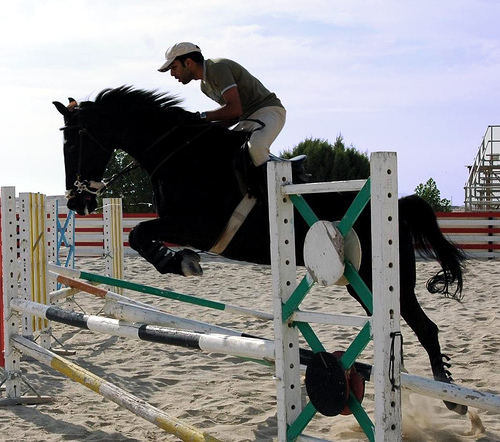

In [6]:
dataset[0][0]

### Имена классов и числовые метки

Собираем названия объектов из разметки. `target2idx` переводит имя класса в число для модели, а `idx2target` возвращает имя для подписи бокса.


In [7]:
target_names = []

for obj in dataset:
    target_names.extend([x['name'] for x in obj[1]['annotation']['object']])

target_names = list(set(target_names))

In [8]:
target_names

['pottedplant',
 'tvmonitor',
 'aeroplane',
 'cow',
 'train',
 'horse',
 'dog',
 'cat',
 'boat',
 'diningtable',
 'car',
 'bus',
 'motorbike',
 'person',
 'bicycle',
 'bird',
 'chair',
 'sheep',
 'sofa',
 'bottle']

In [9]:
# лейблы для объектов начинаются с 1, 0 - для бэкграунда
target2idx = {
    name: i
    for i, name in enumerate(target_names, start=1)
}
idx2target = {i: name for name, i in target2idx.items()}

target2idx, idx2target

({'pottedplant': 1,
  'tvmonitor': 2,
  'aeroplane': 3,
  'cow': 4,
  'train': 5,
  'horse': 6,
  'dog': 7,
  'cat': 8,
  'boat': 9,
  'diningtable': 10,
  'car': 11,
  'bus': 12,
  'motorbike': 13,
  'person': 14,
  'bicycle': 15,
  'bird': 16,
  'chair': 17,
  'sheep': 18,
  'sofa': 19,
  'bottle': 20},
 {1: 'pottedplant',
  2: 'tvmonitor',
  3: 'aeroplane',
  4: 'cow',
  5: 'train',
  6: 'horse',
  7: 'dog',
  8: 'cat',
  9: 'boat',
  10: 'diningtable',
  11: 'car',
  12: 'bus',
  13: 'motorbike',
  14: 'person',
  15: 'bicycle',
  16: 'bird',
  17: 'chair',
  18: 'sheep',
  19: 'sofa',
  20: 'bottle'})

### Приводим разметку к формату модели

`target_transform` извлекает координаты и классы всех объектов на изображении. На выходе — `boxes`: тензор формы $(N,4)$ с координатами `xmin, ymin, xmax, ymax`, и `labels`: тензор формы $(N,)$ с целочисленными метками. Здесь $N$ — число объектов на одном изображении.


In [10]:
def target_transform(voc_target):
    target = {}

    target['boxes'] = torch.tensor(
        [
            [
                float(x['bndbox']['xmin']),
                float(x['bndbox']['ymin']),
                float(x['bndbox']['xmax']),
                float(x['bndbox']['ymax'])
            ] for x in voc_target['annotation']['object']
        ],
        dtype=torch.float32
    )
    target['labels'] = torch.tensor([target2idx[x['name']] for x in voc_target['annotation']['object']], dtype=torch.int64)

    return target

In [11]:
target_transform(dataset[0][1])

{'boxes': tensor([[ 53.,  87., 471., 420.],
         [158.,  44., 289., 167.]]),
 'labels': tensor([ 6, 14])}

### Проверяем разметку на изображениях

`show` выводит картинку, а `draw_boxes_single_image` добавляет боксы и названия классов. Для отрисовки `PILToTensor()` сохраняет пиксели в диапазоне 0–255; ниже посмотрим один пример и несколько соседних кадров.


In [12]:
from torchvision.utils import draw_bounding_boxes


def show(imgs):
    to_pil = T.ToPILImage()

    if not isinstance(imgs, list):
        imgs = [imgs]
    fix, axs = plt.subplots(ncols=len(imgs), squeeze=False, figsize=(16, 8))
    for i, img in enumerate(imgs):
        img = img.detach()
        img = to_pil(img)
        axs[0, i].imshow(np.asarray(img))
        axs[0, i].set(xticklabels=[], yticklabels=[], xticks=[], yticks=[])

def draw_boxes_single_image(image, boxes, labels):
    colors = ["red" for _ in boxes]

    show(draw_bounding_boxes(image, boxes, labels, colors=colors, width=5))

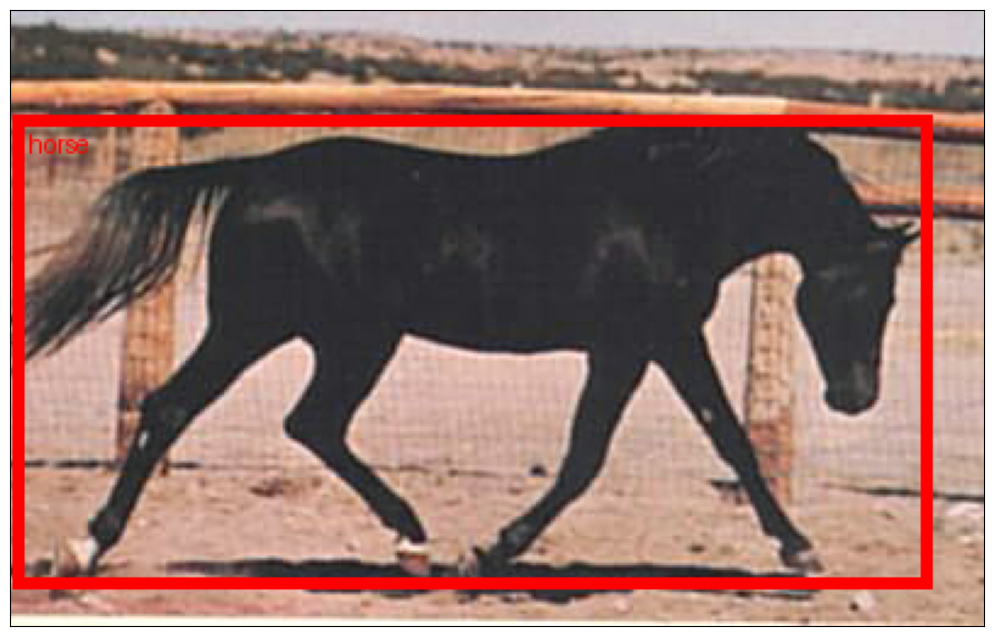

In [17]:
index = 105
draw_boxes_single_image(
    T.PILToTensor()(dataset[index][0]),
    target_transform(dataset[index][1])['boxes'],
    [idx2target[label.item()] for label in target_transform(dataset[index][1])['labels']]
)

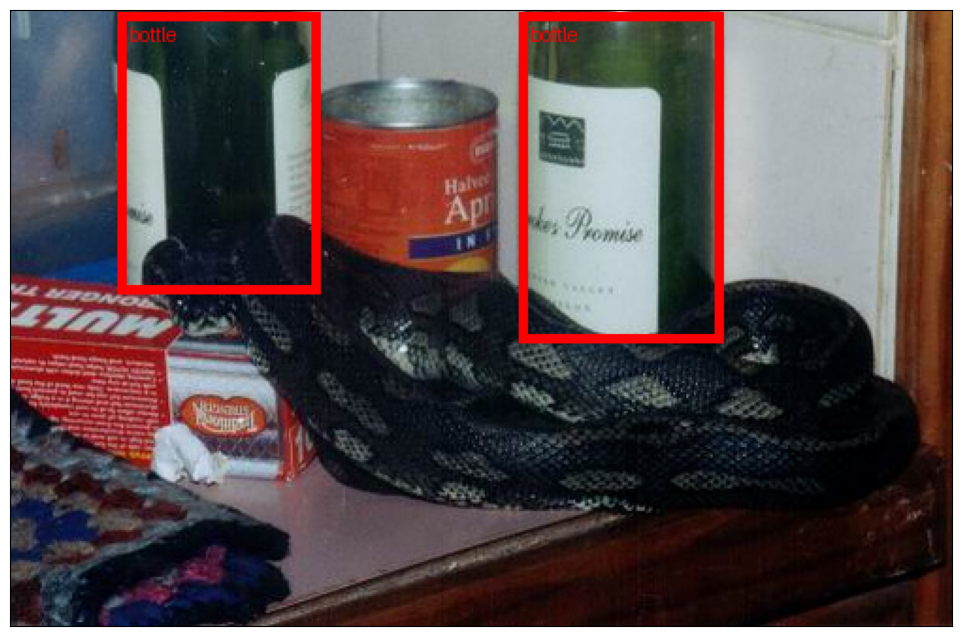

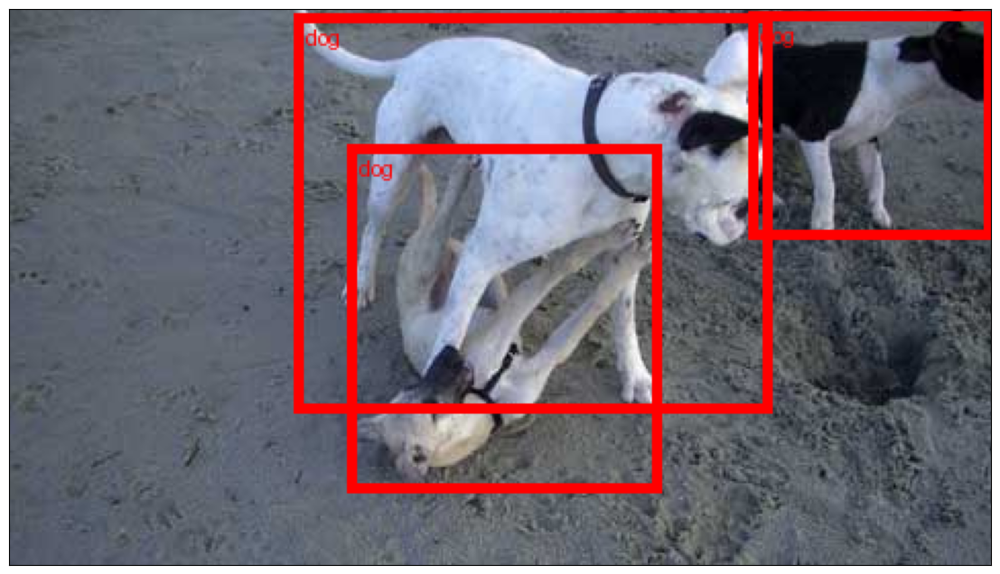

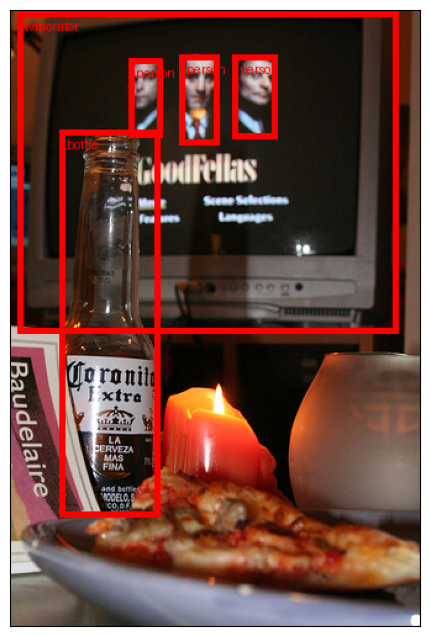

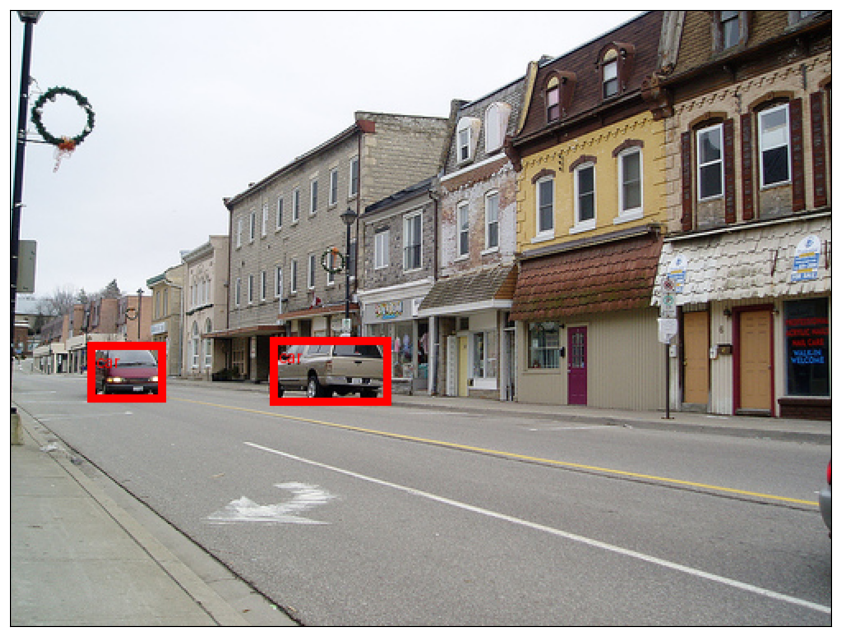

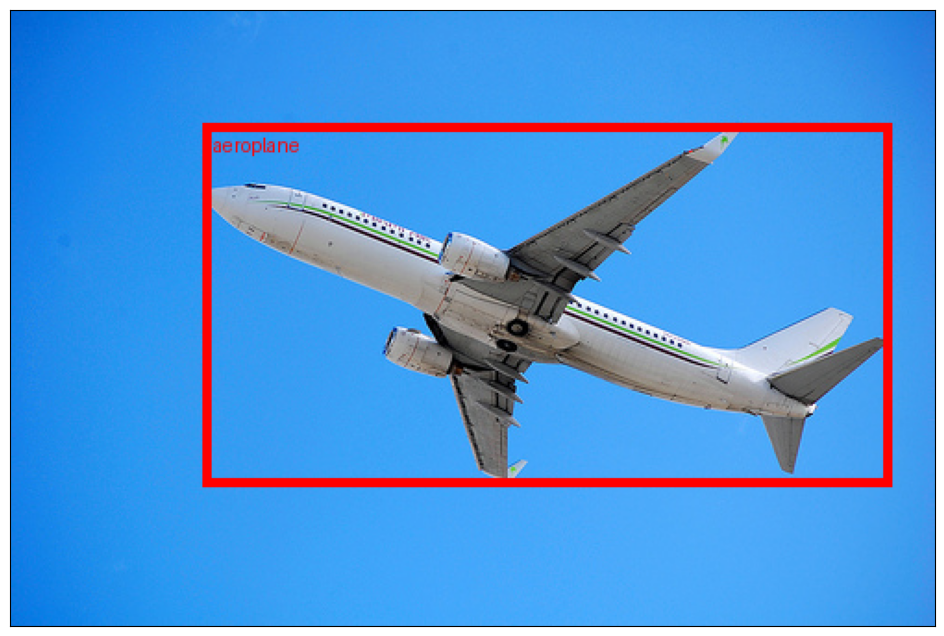

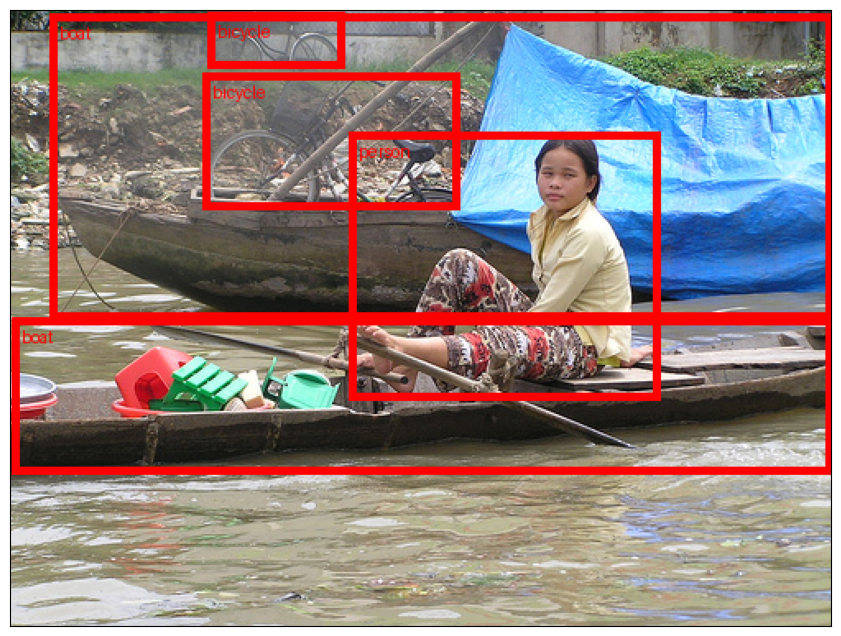

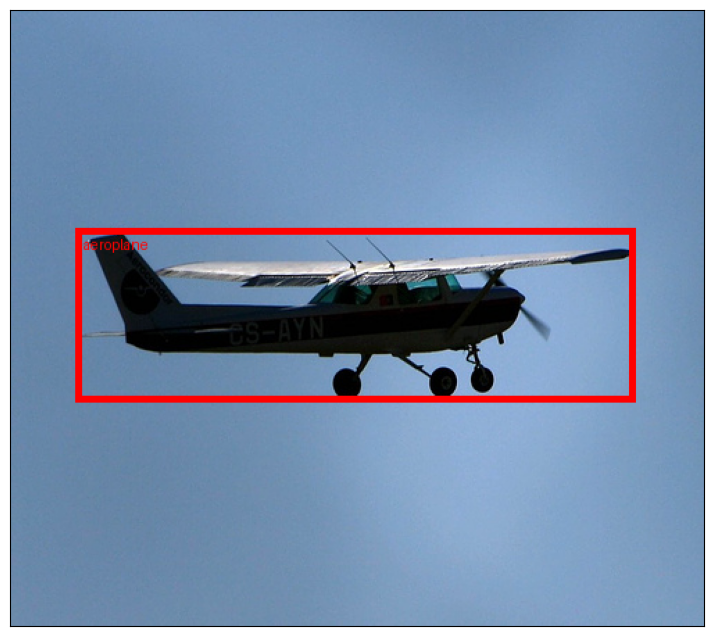

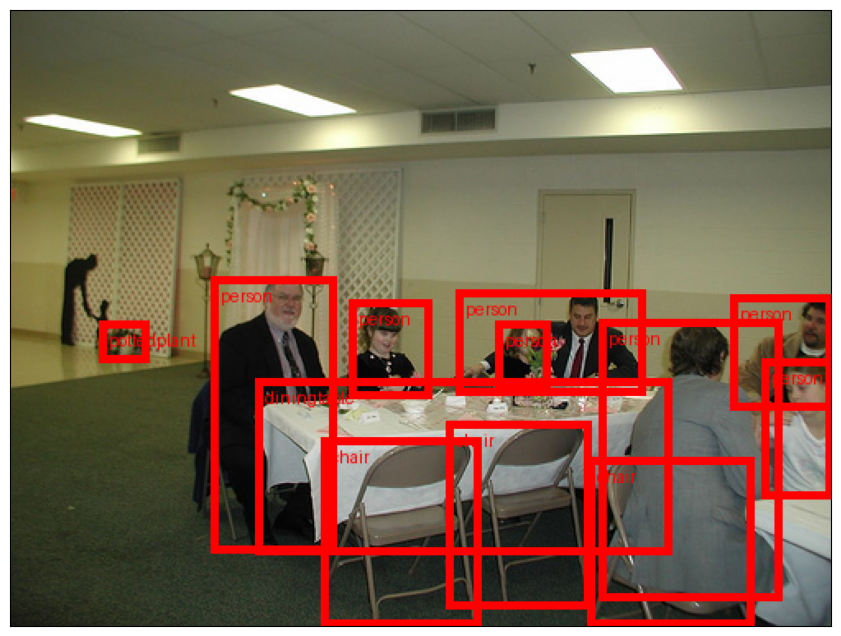

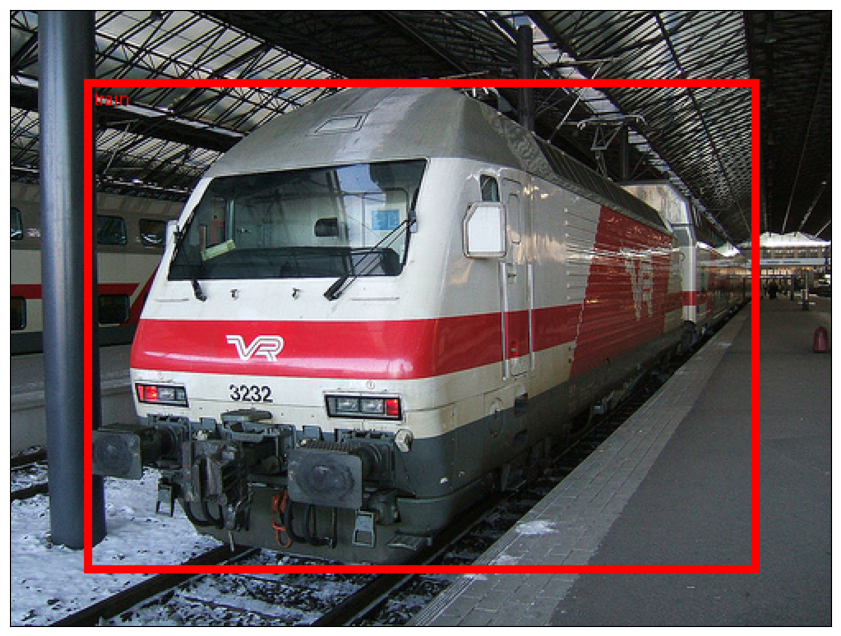

In [18]:
for i in range(1, 10):
    draw_boxes_single_image(
        T.PILToTensor()(dataset[i][0]),
        target_transform(dataset[i][1])['boxes'],
        [idx2target[label.item()] for label in target_transform(dataset[i][1])['labels']]
    )

### Собираем батчи: `collate_fn` и DataLoader

У изображений разные размеры и разное число объектов. `tuple(zip(*batch))` собирает отдельно последовательность изображений и последовательность словарей разметки, не складывая их в общий тензор.

`ToTensor()` переводит изображение в формат $(3,H,W)$ и диапазон 0–1. `batch_size=8` задаёт число изображений в батче; `shuffle=True` перемешивает train, а `num_workers` задаёт число процессов загрузки данных.


In [19]:
def collate_fn(batch):
    return tuple(zip(*batch))

dataset_train = VOCDetection(
    '/data',
    image_set='train',
    transform=T.ToTensor(),
    target_transform=target_transform
)

dataset_test = VOCDetection(
    '/data',
    image_set='val',
    transform=T.ToTensor(),
    target_transform=target_transform
)

train_loader = DataLoader(dataset_train, batch_size=8, shuffle=True, num_workers=8, pin_memory=True, collate_fn=collate_fn)
valid_loader = DataLoader(dataset_test, batch_size=8, shuffle=False, num_workers=8, pin_memory=True, collate_fn=collate_fn)

### Загружаем Faster R-CNN

`get_detection_model()` загружает предобученный Faster R-CNN с MobileNetV3 и заменяет классификатор `box_predictor`. `1024` — размер признаков на входе новой головы, `len(target_names)` — число её выходов.

**Особенность исходного кода:** метки здесь начинаются с 0. В torchvision 0 зарезервирован для фона: корректная настройка для $C$ классов объектов требует меток 1…$C$ и $C+1$ выходов. При дословном переносе эту особенность исходника сохраняем.


In [20]:
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor


def get_detection_model():
    model = fasterrcnn_mobilenet_v3_large_320_fpn(weights="DEFAULT")

    model.roi_heads.box_predictor = FastRCNNPredictor(1024, len(target_names) + 1) # не забываем добавить бэкграунд

    return model

In [21]:
from torchvision import transforms

transforms.Resize

torchvision.transforms.transforms.Resize

In [22]:
model = get_detection_model()

model

FasterRCNN(
  (transform): GeneralizedRCNNTransform(
      Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
      Resize(min_size=(320,), max_size=640, mode='bilinear')
  )
  (backbone): BackboneWithFPN(
    (body): IntermediateLayerGetter(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): FrozenBatchNorm2d(16, eps=1e-05)
        (2): Hardswish()
      )
      (1): InvertedResidual(
        (block): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=16, bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
            (2): ReLU(inplace=True)
          )
          (1): Conv2dNormActivation(
            (0): Conv2d(16, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
            (1): FrozenBatchNorm2d(16, eps=1e-05)
          )
        )
      )
      (2): InvertedResidual(
        (block): 

### IoU, NMS и сравнение с разметкой

`intersection_over_union` считает IoU двух боксов. `apply_nms` получает индексы боксов, оставшихся после NMS, и по ним отбирает координаты, классы и уверенности. `iou_thresh=0.3` — порог перекрытия для подавления дубликатов; NMS применяется отдельно по классам.

`visualize` показывает эталон слева и предсказание справа. `model.eval()` включает режим предсказания, а `@torch.inference_mode()` отключает расчёт градиентов. Дополнительный вызов NMS сохранён из исходника; у Faster R-CNN есть и встроенный NMS.


In [23]:
from torchmetrics.detection.mean_ap import MeanAveragePrecision
from torchvision.ops import batched_nms


def intersection_over_union(dt_bbox, gt_bbox):
    int_x0 = max(dt_bbox[0], gt_bbox[0])
    int_y0 = max(dt_bbox[1], gt_bbox[1])

    int_x1 = min(dt_bbox[2], gt_bbox[2])
    int_y1 = min(dt_bbox[3], gt_bbox[3])

    intersection = max(int_x1 - int_x0, 0) * max(int_y1 - int_y0, 0)
    dt_area = (dt_bbox[2] - dt_bbox[0]) * (dt_bbox[3] - dt_bbox[1])
    gt_area = (gt_bbox[2] - gt_bbox[0]) * (gt_bbox[3] - gt_bbox[1])

    return intersection / (dt_area + gt_area - intersection)


def apply_nms(orig_prediction, iou_thresh=0.3):

    keep = batched_nms(orig_prediction['boxes'], orig_prediction['scores'], orig_prediction['labels'], iou_thresh)

    final_prediction = orig_prediction

    final_prediction['boxes'] = final_prediction['boxes'][keep]
    final_prediction['scores'] = final_prediction['scores'][keep]
    final_prediction['labels'] = final_prediction['labels'][keep]

    return final_prediction


@torch.inference_mode()
def visualize(model, batch):
    model.eval()

    to_pil = T.ToPILImage()
    to_tensor = T.PILToTensor()

    xs, ys = batch

    for i, (x, y) in enumerate(zip(xs, ys)):
        prediction = {k: v.to(device) for k, v in model([x.to(device)])[0].items()}

        prediction = apply_nms(prediction)

        # отобразим предикшены только с уверенностью >= 0.5
        keep = prediction["scores"] >= 0.5
        prediction = {
            key: value[keep]
            for key, value in prediction.items()
        }

        x = to_tensor(to_pil(x.cpu()))

        true_boxes = draw_bounding_boxes(x, boxes=y['boxes'], labels=[idx2target[label.item()] for label in y['labels']], width=5, colors='red')
        predicted_boxes = draw_bounding_boxes(x, boxes=prediction['boxes'], labels=[idx2target[label.item()] for label in prediction['labels']], width=5, colors='red')

        fig, ax = plt.subplots(1, 2, figsize=(20, 10), facecolor='white')

        ax[0].imshow(to_pil(true_boxes))
        ax[1].imshow(to_pil(predicted_boxes))

        ax[0].axis('off')
        ax[1].axis('off')

        ax[0].set_title('Target boxes')
        ax[1].set_title('Predicted boxes')

        plt.subplots_adjust(wspace=0, hspace=0.1)
        plt.show()

        if i >= 9:
            break

### Один проход обучения

В режиме `train` вызов `model(x, y)` возвращает словарь компонентов loss, рассмотренных выше. Изображения и разметку переносим на `device`.

| Строка | Что делает |
|---|---|
| `optimizer.zero_grad()` | Обнуляет градиенты предыдущего шага. |
| `loss_sum = sum(...)` | Складывает компоненты ошибки детектора. |
| `loss_sum.backward()` | Вычисляет градиенты параметров. |
| `optimizer.step()` | Обновляет параметры модели. |


In [24]:
def train(model):
    model.train()

    for x, y in tqdm(train_loader, desc='Train'):
        x = list(_.to(device).float() for _ in x)
        y = [{k: v.to(device) for k, v in t.items()} for t in y]

        optimizer.zero_grad()

        output = model(x, y)

        loss_sum = sum(loss for loss in output.values())

        loss_sum.backward()

        optimizer.step()

### Оценка качества

В режиме `eval` вызов `model(x)` возвращает предсказания: `boxes`, `labels`, `scores`. `metric.update(output, y)` накапливает предсказания и эталоны всех батчей, а `metric.compute()['map']` считает итоговый mAP по порогам IoU 0.50…0.95. Градиенты при оценке не нужны.


In [25]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()

    metric = MeanAveragePrecision()

    for x, y in tqdm(loader, desc='Evaluation'):
        x = list(_.to(device).float() for _ in x)

        output = model(x)

        output = [{k: v.cpu() for k, v in t.items()} for t in output]

        metric.update(output, y)

    print("Предикшены собраны. Считаем mAP...", flush=True)
    result = metric.compute()
    return result["map"]

`plot_stats` рисует историю train и validation mAP. В приведённом ниже цикле эта вспомогательная функция не вызывается.


In [26]:
def plot_stats(
    train_map,
    valid_map,
    title
):
    plt.figure(figsize=(16, 8))

    plt.title(title + ' mAP')

    plt.plot(train_map, label='Train mAP')
    plt.plot(valid_map, label='Valid mAP')
    plt.legend()
    plt.grid()

    plt.show()

### Цикл по эпохам

`whole_train_valid_cycle` после каждого прохода по train показывает предсказания на одном и том же validation-батче. Так удобно видеть, как меняются боксы. `clear_output()` убирает предыдущий вывод; численный mAP здесь не вычисляется — его считаем отдельно в конце.


In [27]:
def whole_train_valid_cycle(model, num_epochs, title):
    batch = next(iter(valid_loader))

    for epoch in range(num_epochs):
        train(model)

        clear_output()

        visualize(model, batch)

Создаём модель на GPU или CPU. Adam обновляет параметры с `requires_grad=True`, то есть все обучаемые параметры модели; `lr=1e-4` — скорость обучения.


In [28]:
model = get_detection_model().to(device)

optimizer = Adam([p for p in model.parameters() if p.requires_grad], lr=1e-4)

Давайте попробуем для начала 5 эпох:

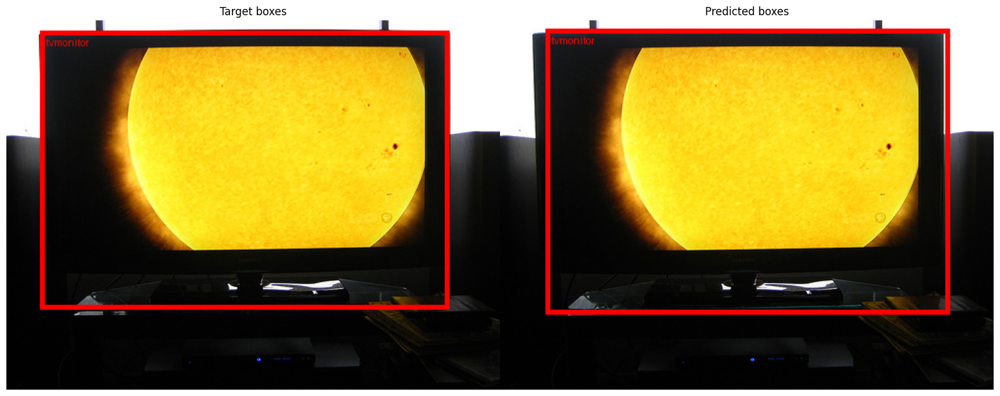

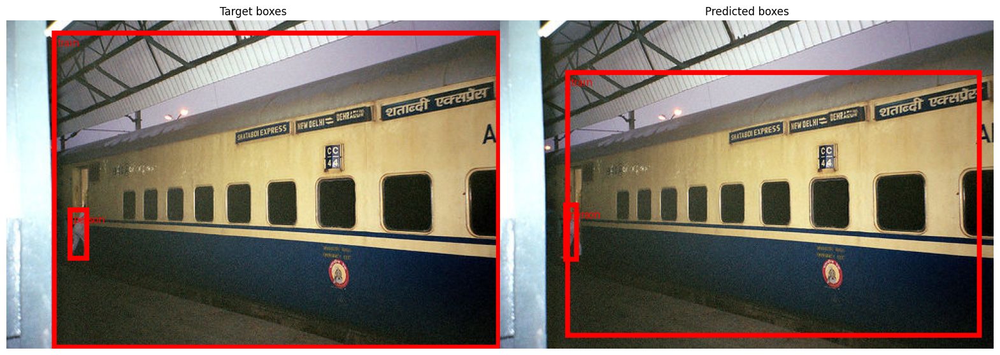

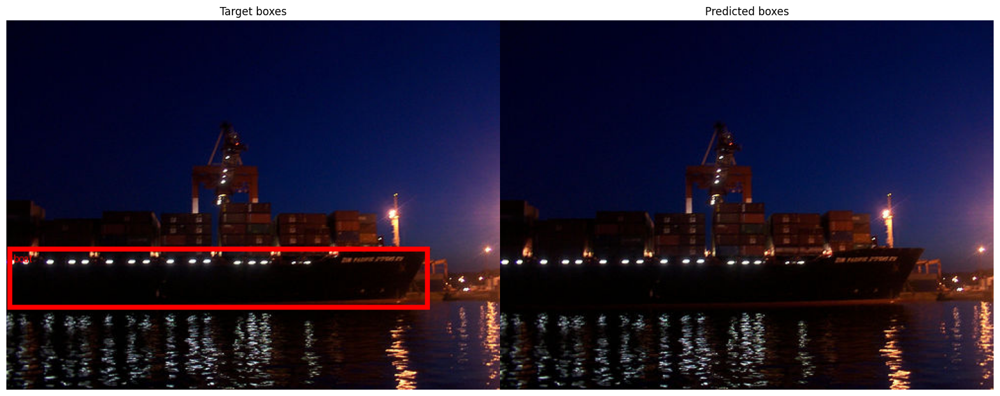

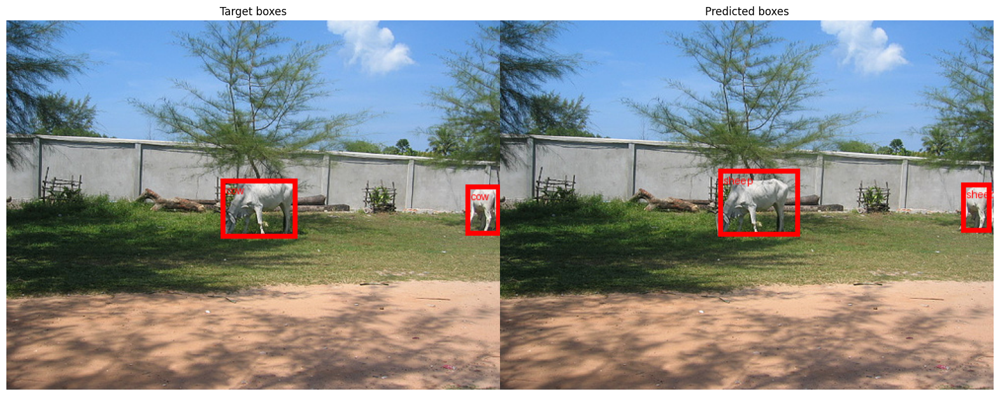

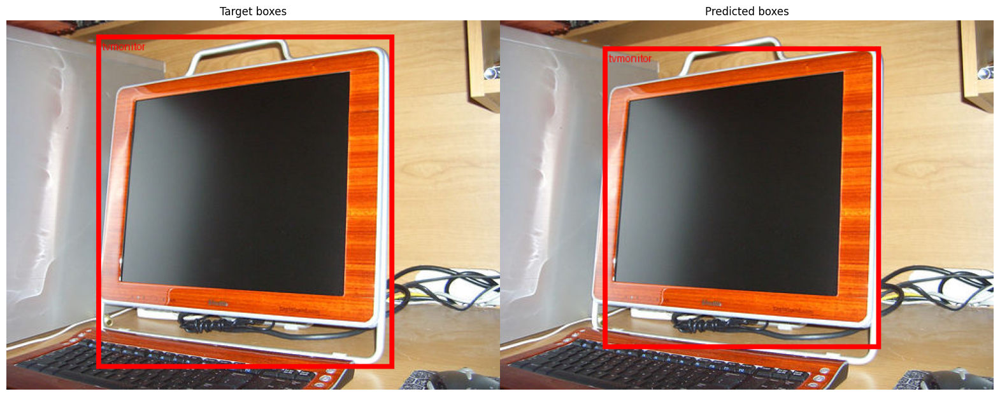

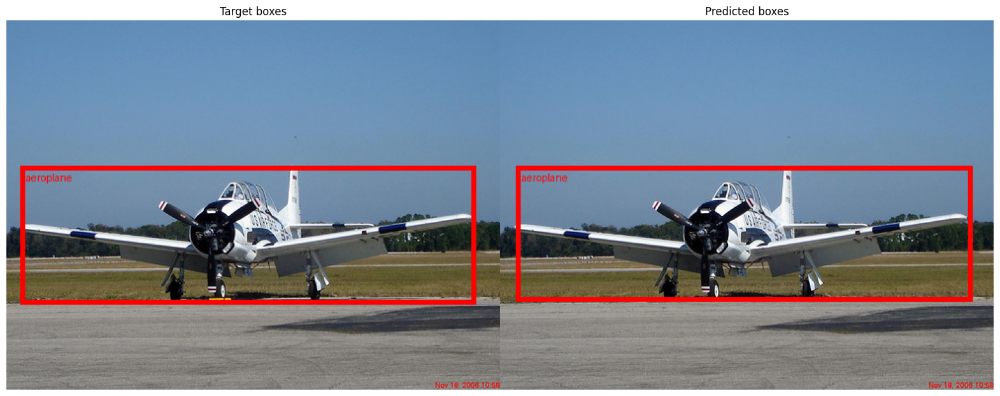

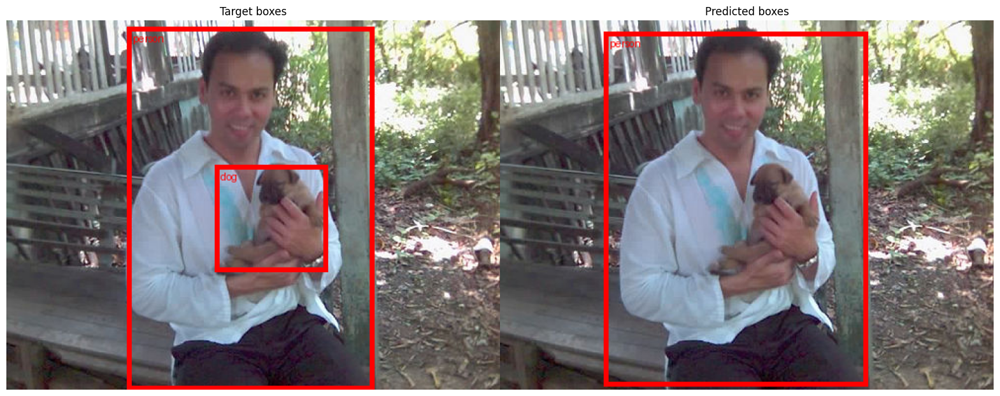

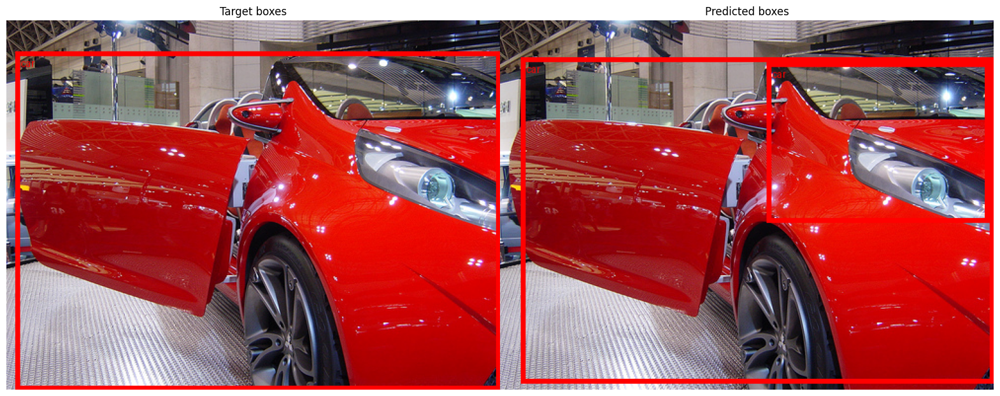

In [74]:
whole_train_valid_cycle(model, 5, 'Faster R-CNN finetune') #~15 минут

In [80]:
torch.save(model.state_dict(), "rcnn_voc.pth")

In [30]:
model.load_state_dict(torch.load("rcnn_voc.pth"))

<All keys matched successfully>

Смотрим предсказания на train-батче.


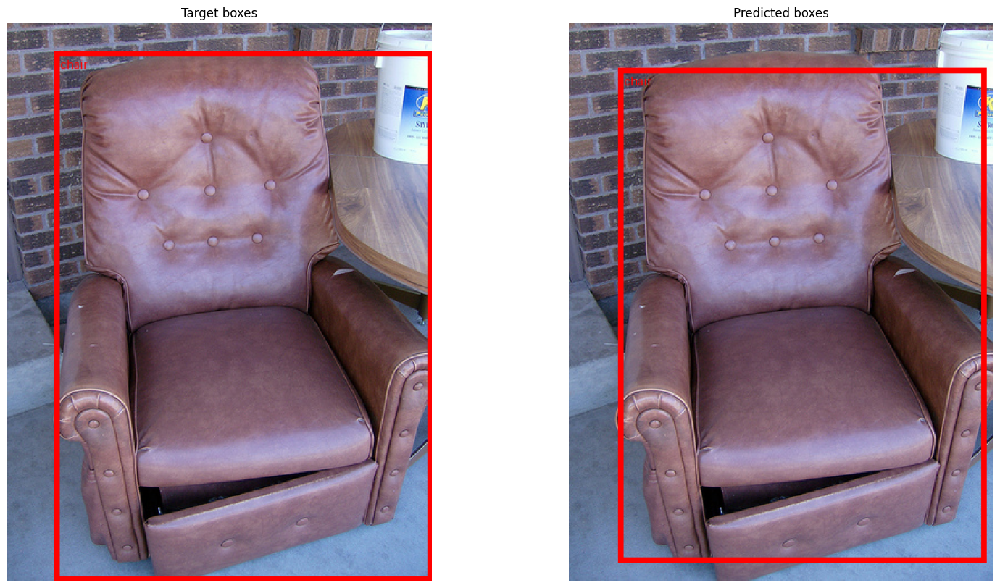

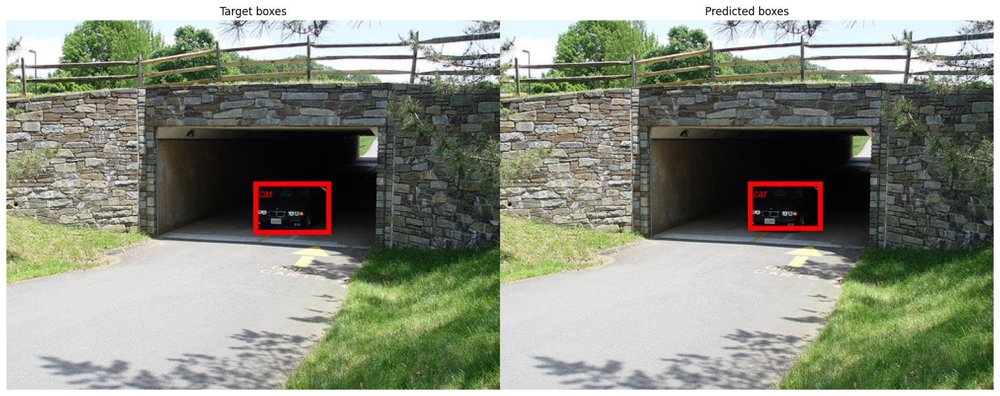

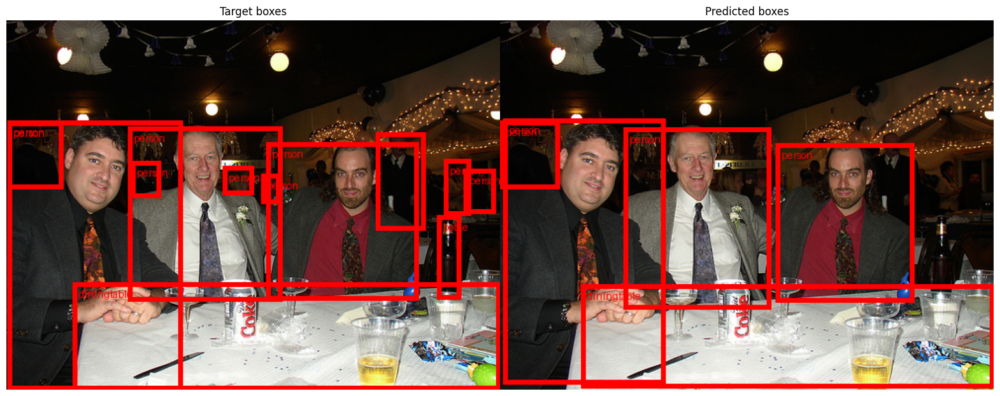

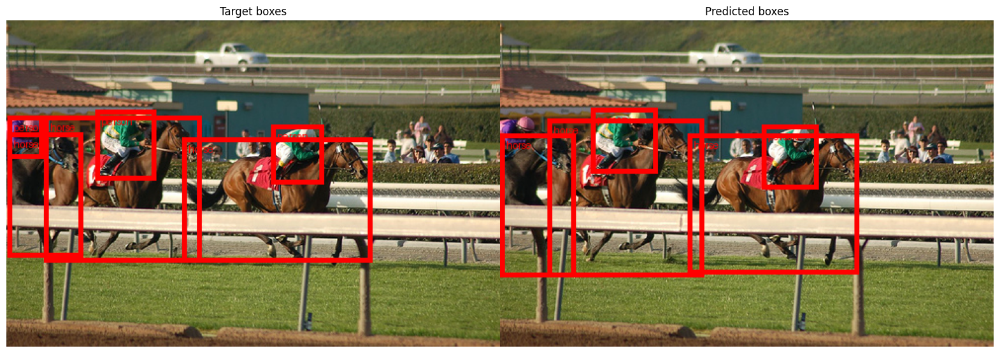

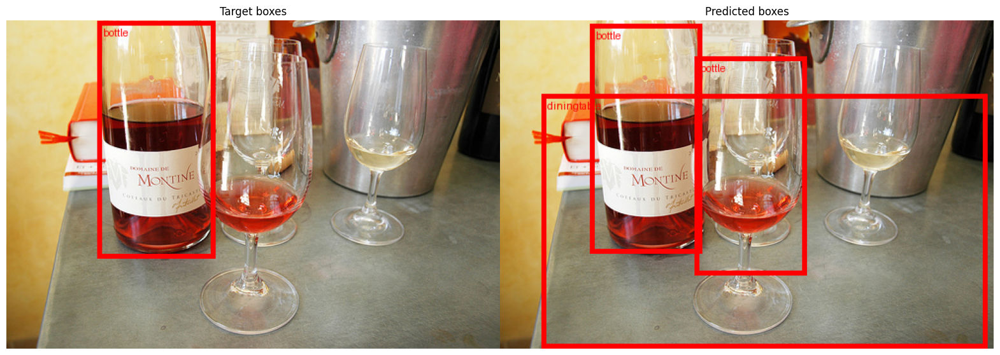

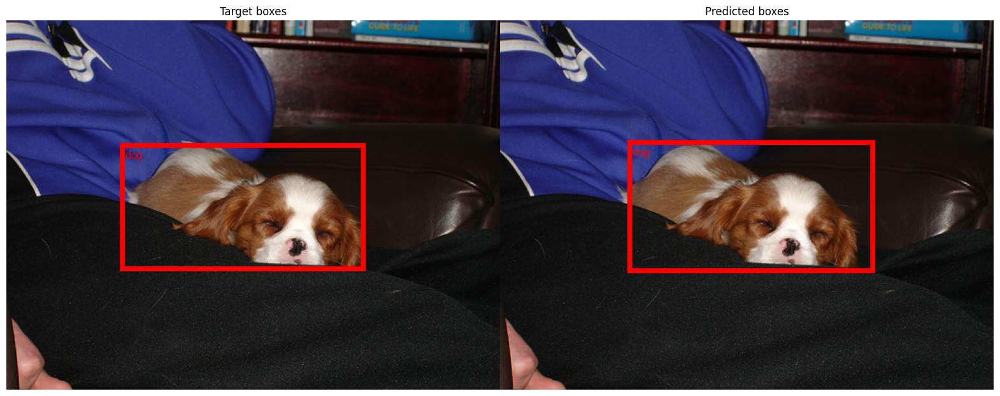

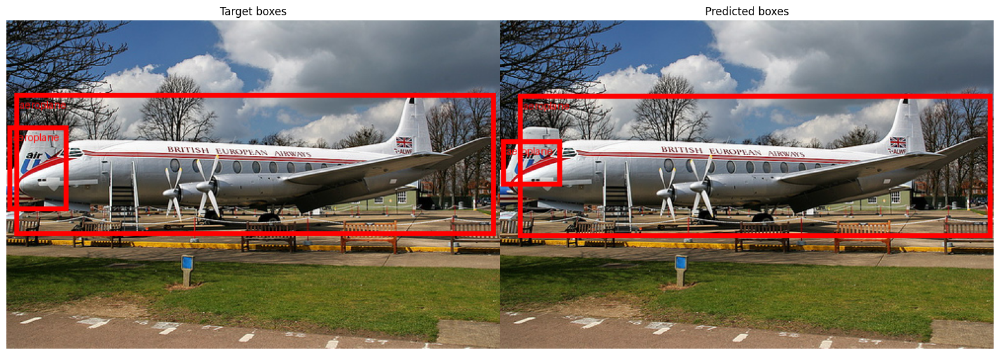

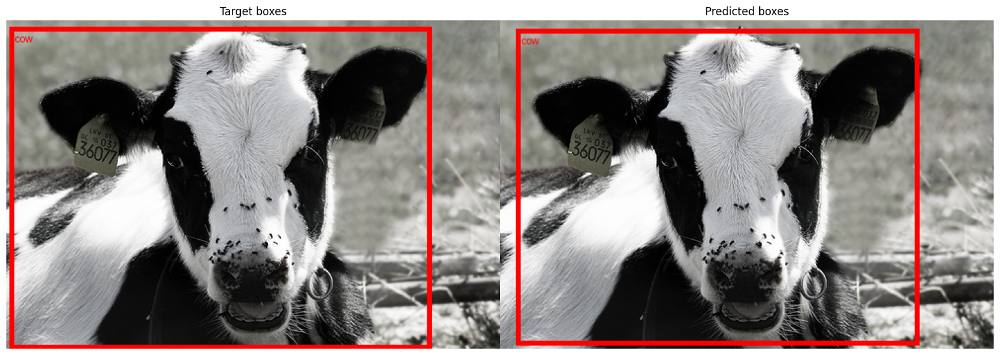

In [75]:
visualize(model, next(iter(train_loader)))

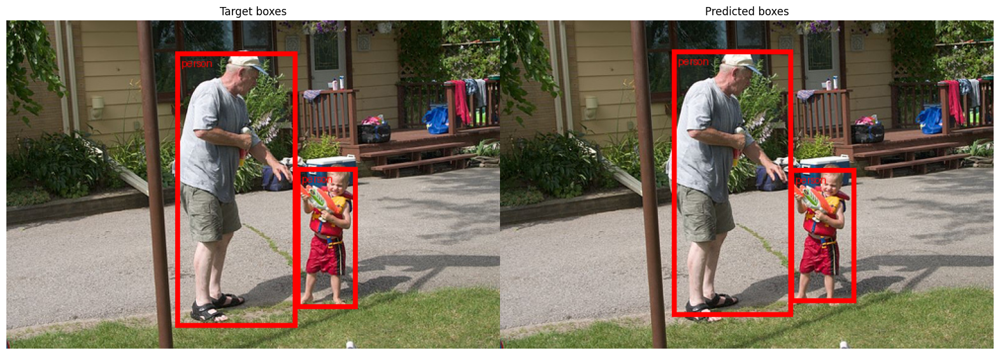

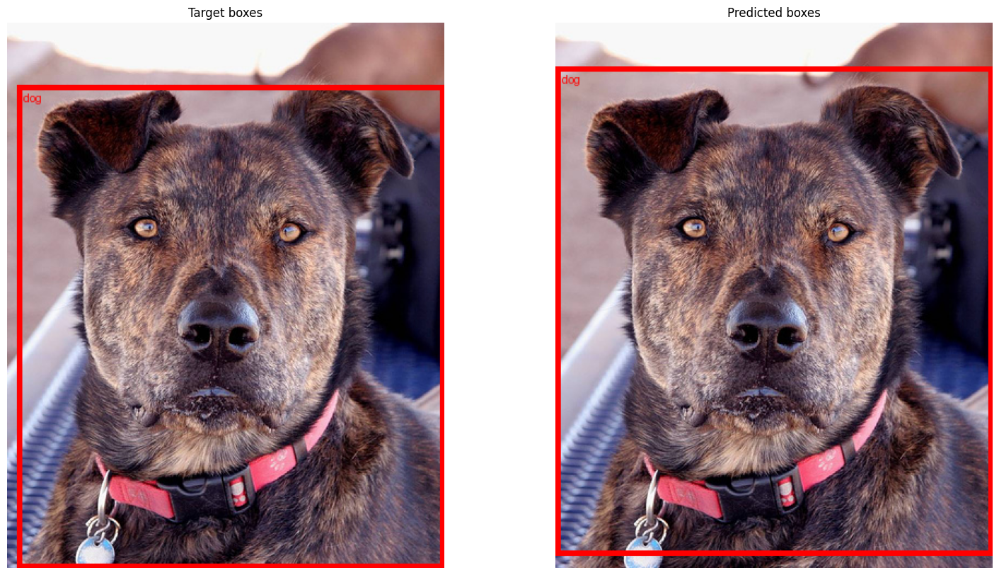

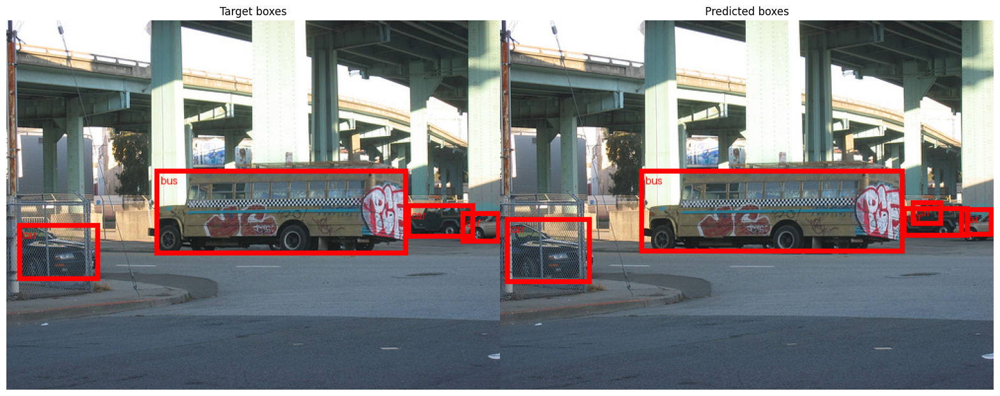

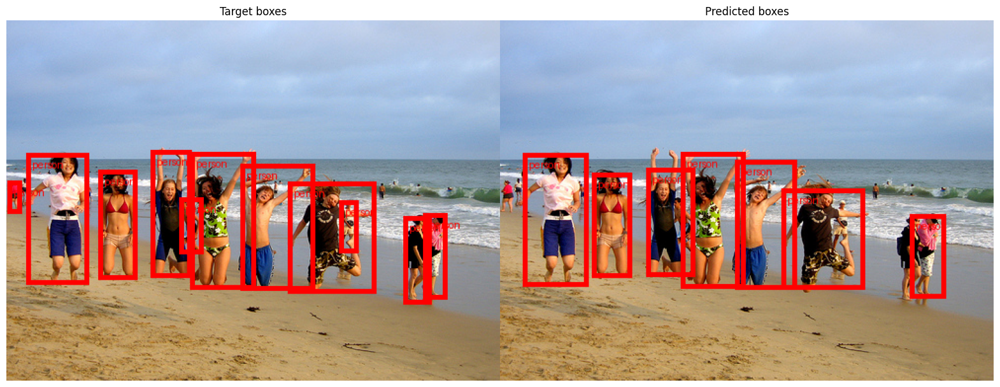

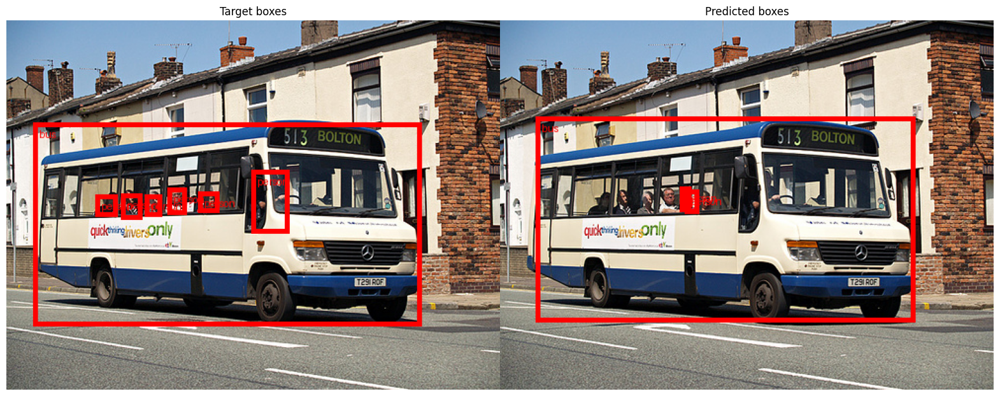

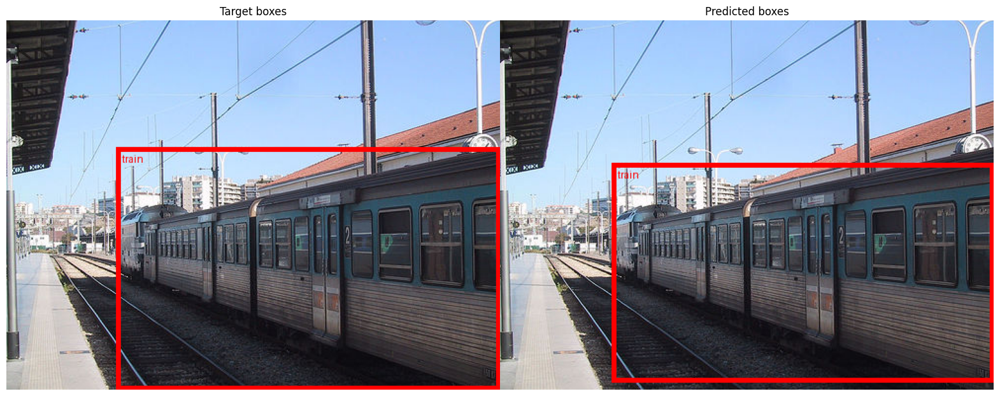

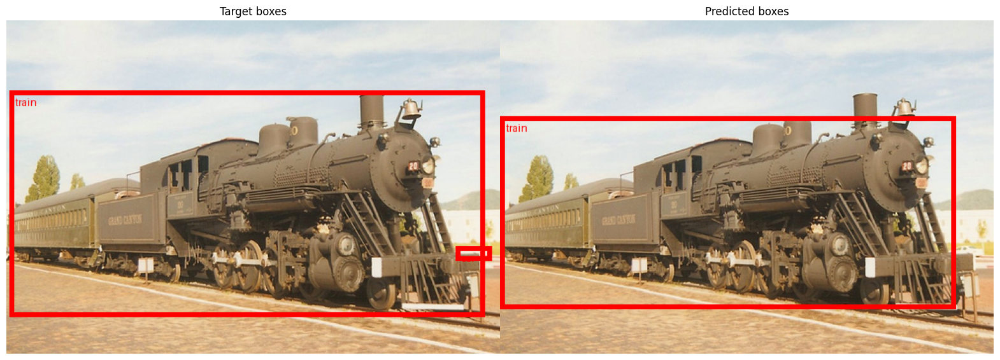

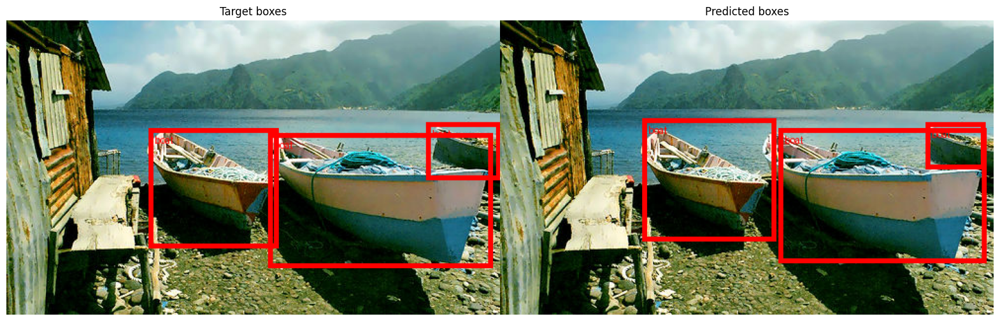

In [76]:
visualize(model, next(iter(train_loader)))

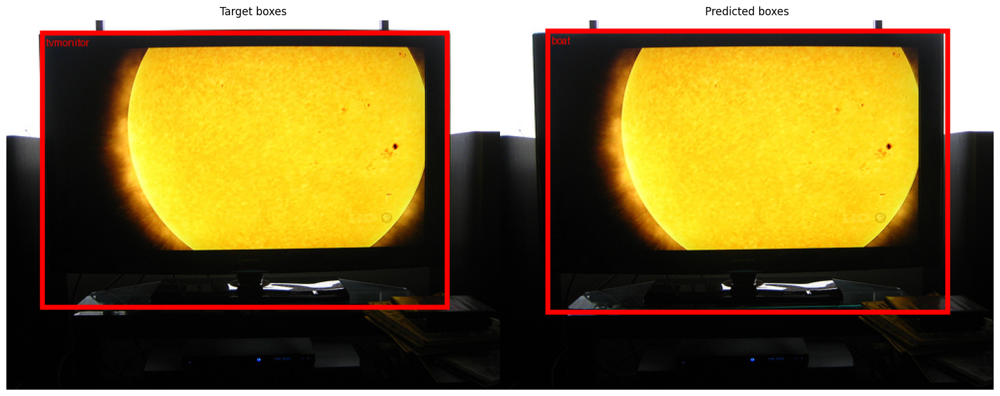

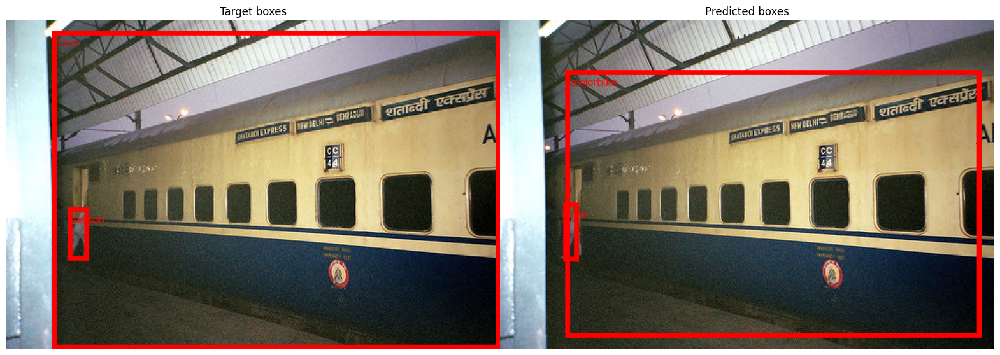

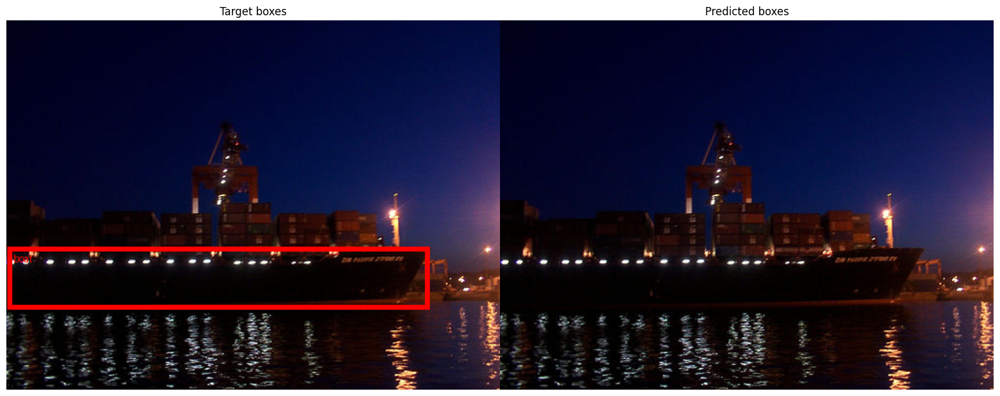

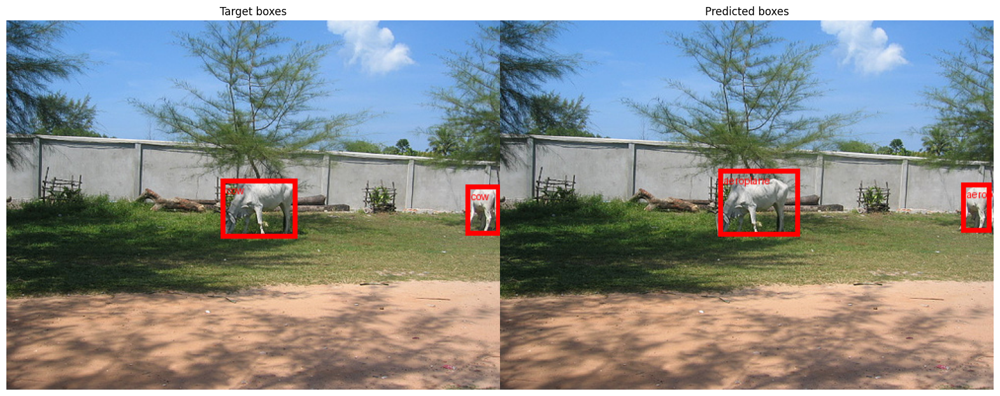

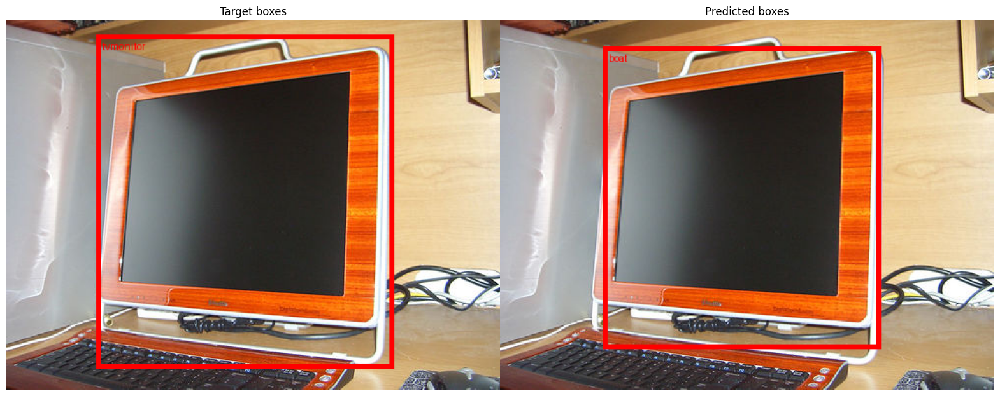

...

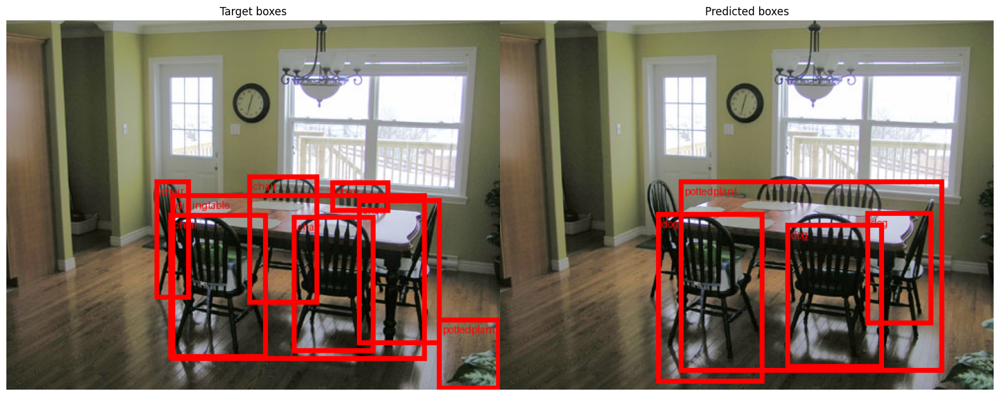

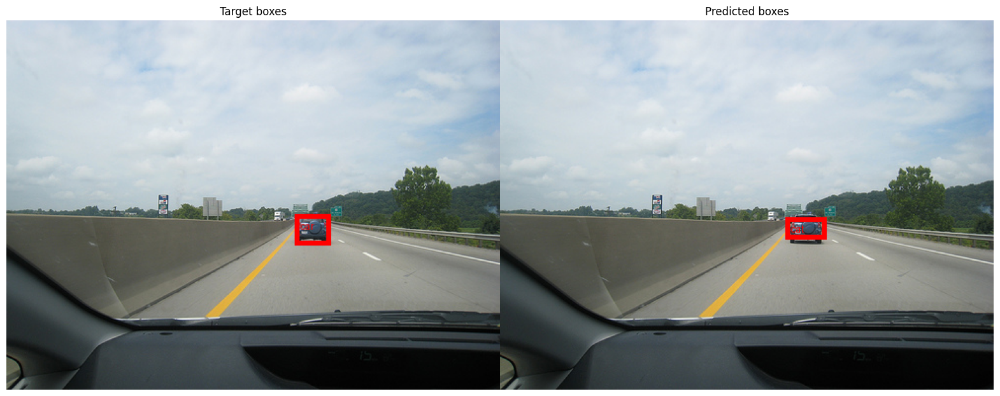

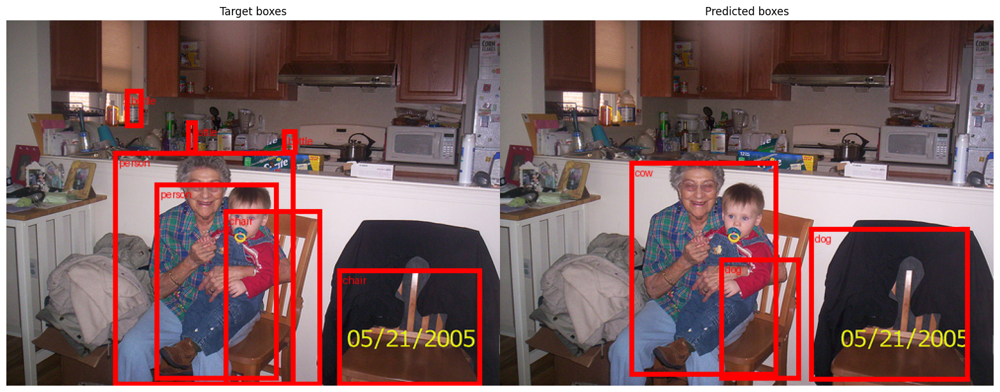

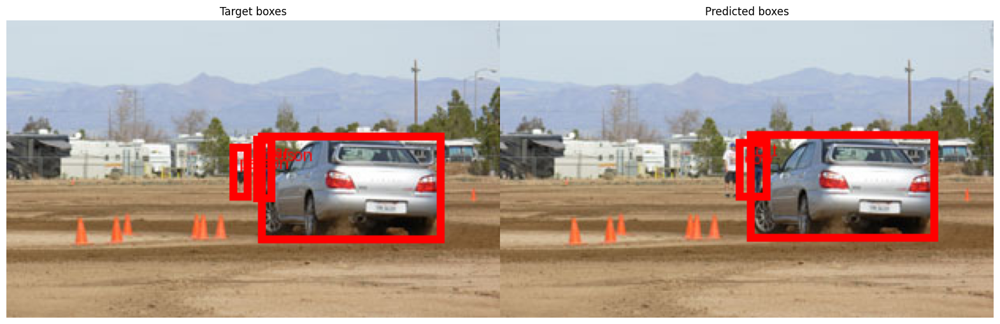

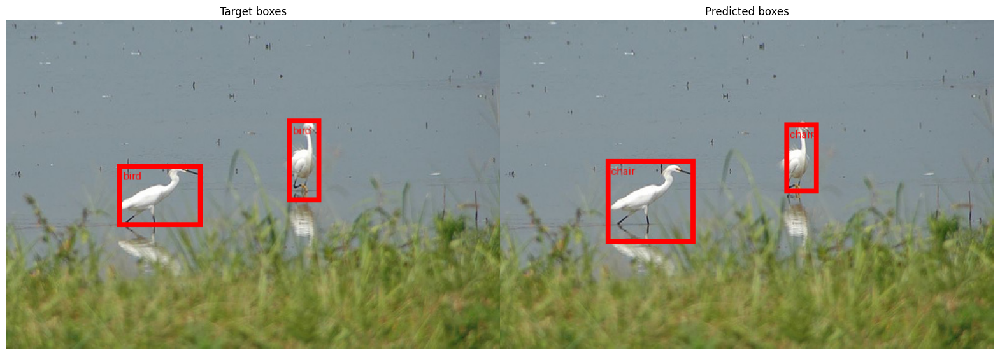

In [43]:
it = iter(valid_loader)
visualize(model, next(it))
visualize(model, next(it))


Считаем mAP отдельно на train и validation:


In [31]:
train_map = evaluate(model, train_loader)
valid_map = evaluate(model, valid_loader)

print(f'Train mAP {train_map:.5f} Valid mAP {valid_map:.5f}')

Evaluation:   0%|          | 0/715 [00:00<?, ?it/s]

/opt/conda/lib/python3.10/site-packages/torch/nn/modules/conv.py:456: UserWarning: Plan failed with a cudnnException: CUDNN_BACKEND_EXECUTION_PLAN_DESCRIPTOR: cudnnFinalize Descriptor Failed cudnn_status: CUDNN_STATUS_NOT_SUPPORTED (Triggered internally at /opt/conda/conda-bld/pytorch_1712608935911/work/aten/src/ATen/native/cudnn/Conv_v8.cpp:919.)
  return F.conv2d(input, weight, bias, self.stride,


Предикшены собраны. Считаем mAP...


Evaluation:   0%|          | 0/728 [00:00<?, ?it/s]

Предикшены собраны. Считаем mAP...
Train mAP 0.03178 Valid mAP 0.02328


## Часть 2. YOLOv8 на кадрах квиддича
### 9. Загружаем датасет «Гарри Поттера»

Теперь вместо VOC используем три класса: **снитч, квоффл и бладжер**. Картинки лежат в `images`, разметка — в `xmls`, имена классов — в `class_dict`.

Повторяем тот же пайплайн, но для обучения готовой YOLO преобразуем XML в её текстовый формат. Используем готовую архитектуру и встроенную функцию потерь.

`class_dict` содержит имена и номера классов; `ast.literal_eval` читает его как словарь. Для YOLO создаём метки 0, 1, 2 и обратный словарь для подписей.


In [35]:
import ast
import shutil
from pathlib import Path
from urllib.request import urlretrieve
from xml.etree import ElementTree as ET
from zipfile import ZipFile

import yaml
from ultralytics import YOLO

SEED = 42

HARRY_ROOT = Path('harry_source')
data_folder = HARRY_ROOT / 'data'

if not (data_folder / 'images').exists():
    HARRY_ROOT.mkdir(exist_ok=True)
    archive_path = HARRY_ROOT / 'harry_data.zip'
    url = 'https://github.com/markblumenau/hw3_iad_dl/raw/main/harry/data.zip'
    urlretrieve(url, archive_path)

    with ZipFile(archive_path) as archive:
        archive.extractall(HARRY_ROOT)

class_file = data_folder / 'class_dict'
raw_classes = ast.literal_eval(class_file.read_text().strip())
ordered_names = sorted(raw_classes, key=raw_classes.get)

# у YOLO классы объектов начинаются с 0; отдельного класса фона нет.
harry_class_to_id = {name: idx for idx, name in enumerate(ordered_names)}
harry_names = {idx: name for name, idx in harry_class_to_id.items()}
print('Классы:', harry_names)

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/home/user/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Классы: {0: 'snitch', 1: 'quaffle', 2: 'bludger'}


In [33]:
%pip install ultralytics

Defaulting to user installation because normal site-packages is not writeable
  Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl.metadata (19 kB)
  Using cached polars-2.0.0-py3-none-any.whl.metadata (11 kB)
  Using cached ultralytics_thop-2.2.2-py3-none-any.whl.metadata (14 kB)
  Using cached polars_runtime_32-2.0.0-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl.metadata (1.5 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 17.5 MB/s eta 0:00:00
Using cached opencv_python-5.0.0.93-cp37-abi3-manylinux_2_28_x86_64.whl (73.8 MB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.8/16.8 MB 56.9 MB/s eta 0:00:00a 0:00:01
Using cached polars-2.0.0-py3-none-any.whl (876 kB)
Using cached polars_runtime_32-2.0.0-cp310-abi3-manylinux_2_17_x86_64.manylinux2014_x86_64.whl (54.5 MB)
Using cached ultralytics_thop-2.2.2-py3-none-any.whl (32 kB)

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrad

In [34]:
%pip install numpy==1.26.4

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 18.2/18.2 MB 39.6 MB/s eta 0:00:00a 0:00:01
  Attempting uninstall: numpy
    Found existing installation: numpy 2.2.6
    Uninstalling numpy-2.2.6:
      Successfully uninstalled numpy-2.2.6
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
opencv-python 5.0.0.93 requires numpy>=2; python_version >= "3.9", but you have numpy 1.26.4 which is incompatible.

[notice] A new release of pip is available: 24.3.1 -> 26.2.1
[notice] To update, run: python -m pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


### Читаем XML и разделяем кадры

`read_harry_target` возвращает тот же словарь `boxes` и `labels`, что и в первой практике. Координаты ограничиваем размером кадра, боксы с нулевой или отрицательной площадью пропускаем.

Разделяем изображения на 90% train и 10% validation. `SEED` фиксирует разбиение, а `assert` проверяет, что один файл не попал в обе части. Затем показываем разметку функцией из первой практики.


Train / validation: 226 57


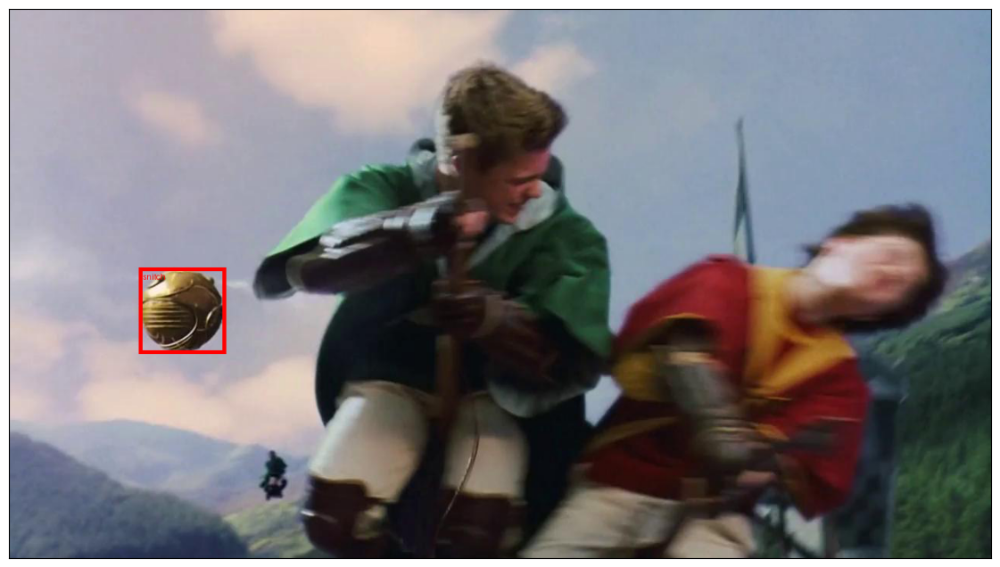

In [36]:
def read_harry_target(image_path):
    xml_path = data_folder / 'xmls' / (image_path.stem + '.xml')
    annotation = ET.parse(xml_path).getroot()
    boxes = []
    labels = []

    with Image.open(image_path) as image:
        width, height = image.size

    for obj in annotation.findall('object'):
        box = obj.find('bndbox')
        xmin = max(0.0, float(box.findtext('xmin')))
        ymin = max(0.0, float(box.findtext('ymin')))
        xmax = min(float(width), float(box.findtext('xmax')))
        ymax = min(float(height), float(box.findtext('ymax')))

        if xmax <= xmin or ymax <= ymin:
            continue

        boxes.append([xmin, ymin, xmax, ymax])
        labels.append(harry_class_to_id[obj.findtext('name')])

    return {
        'boxes': torch.tensor(boxes, dtype=torch.float32).reshape(-1, 4),
        'labels': torch.tensor(labels, dtype=torch.int64),
    }


image_paths = sorted(
    path for path in (data_folder / 'images').iterdir()
    if path.suffix.lower() in {'.jpg', '.jpeg', '.png'}
)
rng = np.random.default_rng(SEED)
order = rng.permutation(len(image_paths))
split = int(0.8 * len(order)) # тут можноо менять размер валидации

harry_train_paths = [image_paths[idx] for idx in order[:split]]
harry_valid_paths = [image_paths[idx] for idx in order[split:]]
assert set(harry_train_paths).isdisjoint(harry_valid_paths)
print('Train / validation:', len(harry_train_paths), len(harry_valid_paths))

example_path = harry_train_paths[0]
image = Image.open(example_path).convert('RGB')
target = read_harry_target(example_path)
draw_boxes_single_image(
    T.PILToTensor()(image),
    target['boxes'],
    [harry_names[int(label)] for label in target['labels']],
)

### 10. Подготовим формат YOLO

На каждый кадр приходится текстовый файл с тем же именем. Одна строка — один объект: `class_id cx cy width height`. Центр и размеры нормированы на **размеры именно этого изображения**, а не общего батча.

$$c_x=\frac{x_{min}+x_{max}}{2W},\qquad
c_y=\frac{y_{min}+y_{max}}{2H},\qquad
w=\frac{x_{max}-x_{min}}{W},\qquad
h=\frac{y_{max}-y_{min}}{H}.$$

Создаём папки `images/train`, `images/val`, `labels/train`, `labels/val` и YAML с путями и именами классов. Отдельный `Dataset` и `collate_fn` для YOLO не пишем: библиотека создаёт их сама.

In [37]:
def export_yolo_split(image_paths, split_name, output_root):
    image_folder = output_root / 'images' / split_name
    label_folder = output_root / 'labels' / split_name
    image_folder.mkdir(parents=True, exist_ok=True)
    label_folder.mkdir(parents=True, exist_ok=True)

    for image_path in image_paths:
        with Image.open(image_path) as image:
            width, height = image.size  # пересчитываем размеры для каждого кадра

        target = read_harry_target(image_path)
        lines = []

        for box, label in zip(target['boxes'], target['labels']):
            xmin, ymin, xmax, ymax = box.tolist()
            cx = (xmin + xmax) / (2 * width)
            cy = (ymin + ymax) / (2 * height)
            box_width = (xmax - xmin) / width
            box_height = (ymax - ymin) / height

            line = (
                f'{int(label)} {cx:.6f} {cy:.6f} '
                f'{box_width:.6f} {box_height:.6f}'
            )
            lines.append(line)

        shutil.copy2(image_path, image_folder / image_path.name)
        label_path = label_folder / (image_path.stem + '.txt')
        label_path.write_text('\n'.join(lines), encoding='utf-8')

Вызываем `export_yolo_split` отдельно для train и validation. Функция копирует картинки и записывает TXT-разметку. `data.yaml` сообщает YOLO корневую папку датасета, пути к двум частям и соответствие числовых меток названиям классов.


In [38]:
YOLO_ROOT = Path('harry_yolo')
export_yolo_split(harry_train_paths, 'train', YOLO_ROOT)
export_yolo_split(harry_valid_paths, 'val', YOLO_ROOT)

config = {
    'path': str(YOLO_ROOT.resolve()),
    'train': 'images/train',
    'val': 'images/val',
    'names': harry_names,
}
yaml_path = YOLO_ROOT / 'data.yaml'
yaml_path.write_text(
    yaml.safe_dump(config, sort_keys=False, allow_unicode=True),
    encoding='utf-8',
)
print(yaml_path.read_text())

path: /code/GitHub/intro-to-dl-hse/seminars/242/harry_yolo
train: images/train
val: images/val
names:
  0: snitch
  1: quaffle
  2: bludger



### Аугментации

Геометрические преобразования должны менять и картинку, и боксы. В этой практике YOLO сама выполняет resize/letterbox, преобразование разметки и аугментации train-изображений. Для простоты отключим Mosaic и MixUp, оставив стандартные цветовые и геометрические преобразования, включая горизонтальное отражение. На validation случайных обучающих аугментаций нет **и быть не должно!**.

### 11. Загружаем готовую YOLOv8n и дообучаем

`yolov8n.pt` — маленькая модель с предобученными весами COCO. Загружаем веса, затем дообучаем на трёх классах квиддича. Запустить только COCO-модель недостаточно: она не имеет классов «снитч», «квоффл» и «бладжер».

Для занятия начинаем с тридцати эпох; для более качественной детекции обычно нужно дольше. Loss, подбор соответствий боксов разметке и цикл обучения уже реализованы внутри Ultralytics.

In [39]:
yolo_model = YOLO('yolov8n.pt')
yolo_device = 0 if torch.cuda.is_available() else 'cpu'

В `train()` передаём YAML с данными, число эпох, размер входа `imgsz` и размер батча. YOLO сама создаёт загрузчики, считает loss и обновляет параметры. `workers=0` загружает данные в основном процессе; `amp=False` отключает смешанную точность. Настройки аугментаций явно указаны ниже.


In [40]:
YOLO_EPOCHS = 30

yolo_model.train(
    data=str(yaml_path),
    epochs=YOLO_EPOCHS,
    imgsz=416,
    batch=8,
    device=yolo_device,
    workers=0,
    seed=SEED,
    mosaic=0.0,  # отключаем склейку четырёх изображений
    mixup=0.0,   # отключаем смешивание изображений
    fliplr=0.5,  # отражаем изображение и боксы с вероятностью 0.5
    plots=False,
    amp=False,
)

Ultralytics 8.4.174 🚀 Python-3.10.14 torch-2.3.0 CUDA:0 (NVIDIA GeForce RTX 3090, 24143MiB)
engine/trainer: agnostic_nms=False, amp=False, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=harry_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimiz

/opt/conda/lib/python3.10/site-packages/torch/autograd/graph.py:744: UserWarning: Plan failed with a cudnnException: CUDNN_BACKEND_EXECUTION_PLAN_DESCRIPTOR: cudnnFinalize Descriptor Failed cudnn_status: CUDNN_STATUS_NOT_SUPPORTED (Triggered internally at /opt/conda/conda-bld/pytorch_1712608935911/work/aten/src/ATen/native/cudnn/Conv_v8.cpp:919.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


       1/30      3.48G      1.465      4.465       1.07          2        416: 100% ━━━━━━━━━━━━ 29/29 17.2it/s 1.7s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 13.0it/s 0.3s.6s
                   all         57         62    0.00204      0.585     0.0171     0.0145

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       2/30      3.49G      1.576      3.521      1.082          2        416: 100% ━━━━━━━━━━━━ 29/29 25.1it/s 1.2s0.1s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 24.3it/s 0.2s.1s
                   all         57         62      0.825     0.0139      0.018    0.00752

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size
       3/30      3.49G      1.645      3.302      1.108          2        416: 100% ━━━━━━━━━━━━ 29/29 24.8it/s 1.2s0.1s
                 Class     Images  Instance

KeyboardInterrupt: 

### 12. Оценка и предсказания

Загружаем лучший checkpoint по пути, который вернул trainer.

`best_yolo.val()` оценивает этот checkpoint на validation из YAML. `box.map50` — mAP при IoU 0.50, а `box.map` — среднее по порогам IoU 0.50…0.95.


In [45]:
best_weights = Path(yolo_model.trainer.best)
best_yolo = YOLO(str(best_weights))

harry_metrics = best_yolo.val(
    data=str(yaml_path),
    imgsz=416,
    batch=8,
    device=yolo_device,
    workers=0,
    plots=False,
)
print('mAP@0.50:', round(harry_metrics.box.map50, 3))
print('mAP@[0.50:0.95]:', round(harry_metrics.box.map, 3))

Ultralytics 8.4.174 🚀 Python-3.10.14 torch-2.3.0 CUDA:0 (NVIDIA GeForce RTX 3090, 24143MiB)
Model summary (fused): 72 layers, 3,006,233 parameters, 0 gradients, 8.1 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 7802.3±2333.3 MB/s, size: 64.7 KB)
val: Scanning /code/GitHub/intro-to-dl-hse/seminars/242/harry_yolo/labels/val.cache... 57 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 57/57 10.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 24.5it/s 0.3s0.2s
                   all         57         62       0.84      0.736      0.776      0.501
                snitch         26         26       0.84      0.769      0.786      0.455
               quaffle         24         24      0.858      0.667      0.748      0.504
               bludger         10         12      0.822      0.772      0.794      0.544
Speed: 0.0ms preprocess, 3.2ms inference, 0.0ms loss, 0.2ms postprocess per image
mAP@0.50: 0.

### Показываем предсказания YOLO

`predict` запускает модель на кадре, `conf=0.1` оставляет боксы с уверенностью не ниже 0.1. `plot()` рисует координаты, классы и уверенности. Его результат переводим из BGR в RGB для вывода через matplotlib.


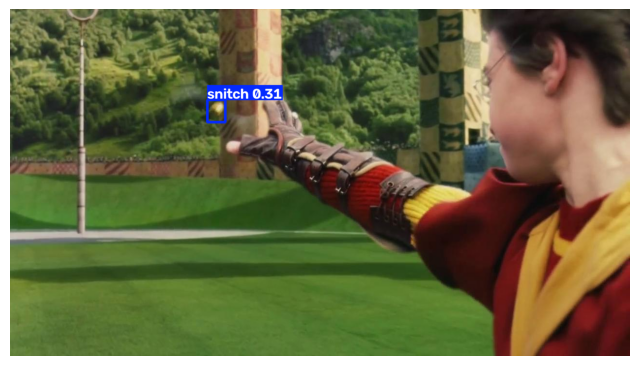

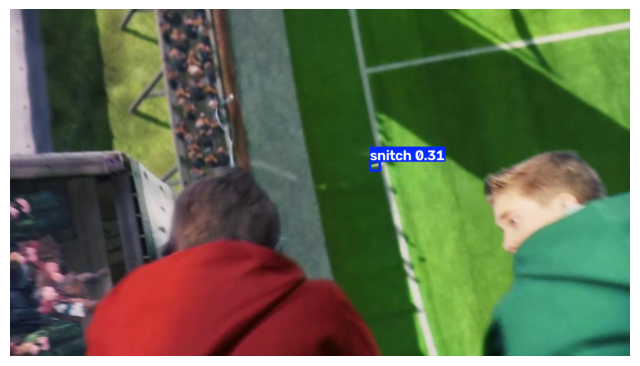

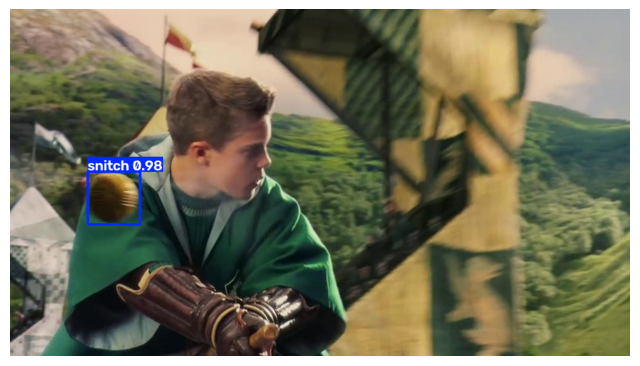

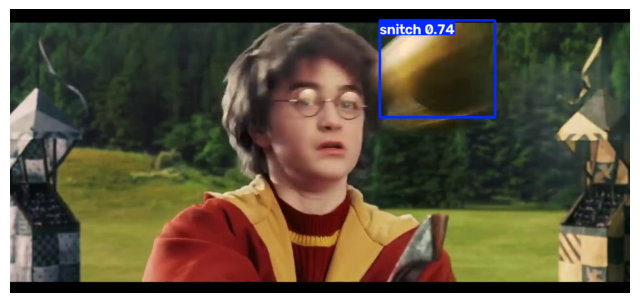

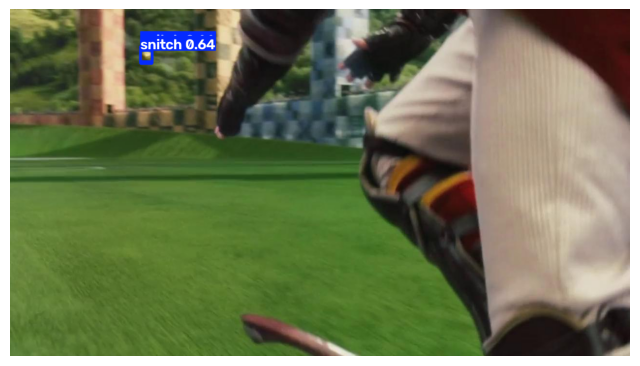

...

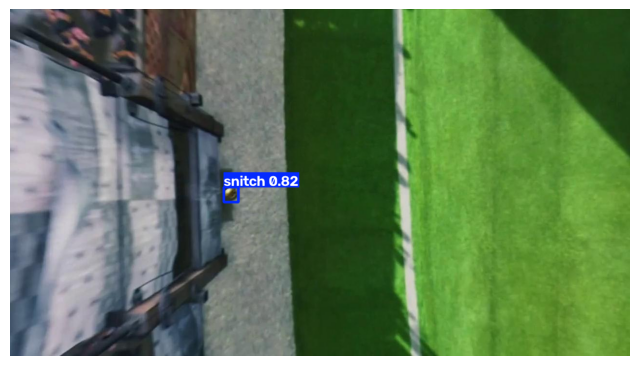

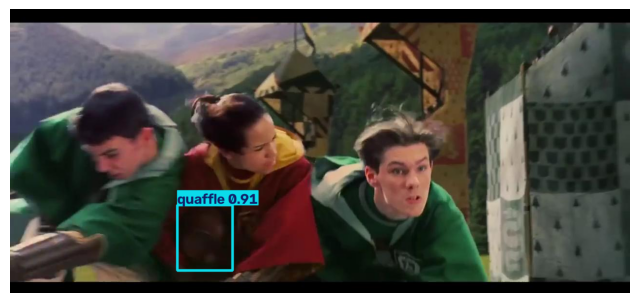

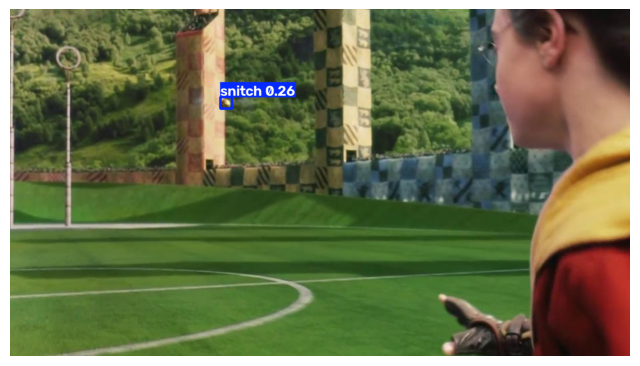

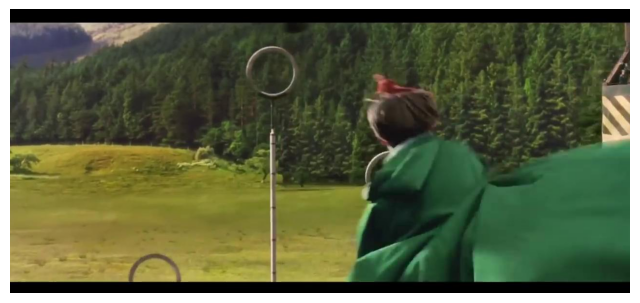

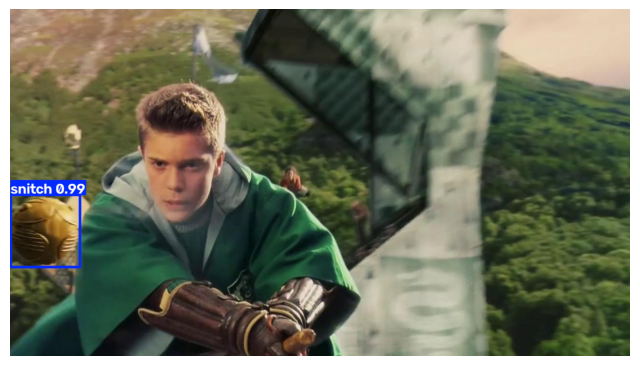

In [47]:
for image_path in harry_valid_paths[:20]:
    result = best_yolo.predict(
        source=str(image_path),
        imgsz=416,
        conf=0.1,
        device=yolo_device,
        verbose=False,
    )[0]

    # YOLO сама рисует боксы, классы и уверенность; plot() возвращает BGR.
    plt.figure(figsize=(8, 5))
    plt.imshow(result.plot()[:, :, ::-1])  # BGR → RGB для matplotlib, чтобы все отрисовалось правильно
    plt.axis('off')
    plt.show()

### 13. Обобщим все то, что рассмотрели в ходе занятия

1. У двух пайплайнов одинаковая цель, при этом Faster R-CNN требует явно написать
`DataLoader` и цикл обучения; YOLO берёт эти шаги на себя после подготовки файлов и YAML.

2. Обе модели уже применяют NMS, поэтому повторно добавлять его к их выходу не требуется. Для улучшения результатов можно увеличить число эпох, подобрать аугментации и разрешение. Случайное разбиение кадров квиддича может завышать качество из-за близких сцен; для полноценного эксперимента лучше разделять по сценам и иметь отдельный test.


**Open-vocabulary detection:** [Grounding DINO](https://arxiv.org/abs/2303.05499) и [YOLO-World](https://arxiv.org/abs/2401.17270) позволяют задавать искомые объекты текстом. Это способ выйти за фиксированный список классов, но качество зависит от запроса и предобучения. Современные трансформерные детекторы, например RT-DETR и RF-DETR, развивают баланс точности и скорости.